# Load data and compute missing metrics & rolling means

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

sns.set_context("talk")


VIDEO_FOLDER = "/home/bw/Projects/c02-fish/Videos"
pd.set_option('display.max_columns', None)
DATA_FOLDER = "tracking_output/"

In [2]:
def compute_radius(x, y, x_center, y_center):
    """Computes the distance between (x, y) and (x_center, y_center)."""
    return ((x - x_center) ** 2 + (y - y_center) ** 2) ** 0.5

assert compute_radius(0, 0, 0, 0) == 0
assert compute_radius(10, 100, 10, 100) == 0
assert compute_radius(100, 0, 0, 0) == 100
assert compute_radius(0, 100, 0, 0) == 100
assert compute_radius(1, 1, 0, 0) == 2 ** 0.5
assert compute_radius(3, 3, 2, 2) == 2 ** 0.5

In [3]:
# Loads the data.
# 
# This reads the csvs individually, adds identifying columns, and then
# at the end concatenates them all into one table and deletes the originals to save memory.
#
# Arguably this is a little fragile, but this way of doing it
# is at least explicit and lets us mark the columns. So no need to get fancy here.

dfs = []
for river in ["Green", "Skagit"]:
    for pH in [1, 2, 3]:
        for trial in range(1, 11):
            # DATA_FOLDER = VIDEO_FOLDER + f"/River-{river}/pH-{pH}/Trial-{trial}/data/"
            for individual in range(0, 6):
                try:
                    indiv = pd.read_csv(DATA_FOLDER + f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.csv")
                    indiv["River"] = river
                    indiv["pH"] = pH
                    indiv["Trial"] = trial
                    indiv["Individual"] = individual
                    dfs.append(indiv)
                except Exception as e:
                    # Pretty noisy, but this lives on as a loud TODO to get these missing videos tracked.
                    print("skipping", f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.")
                    print(e)

df = pd.concat(dfs, ignore_index=True)
del(dfs)


# Manual border distance computation
CENTER_X = 2000
CENTER_Y = 1000
df["radius"] = compute_radius(df["X (cm)"], df["Y (cm)"], CENTER_X, CENTER_Y)

# # Throws out data points with infinite x or y (missing locations)
df = df[~(np.isinf(df["X (cm)"]) | np.isinf(df["Y (cm)"]))]

# # Throws out anomolous points with radius > a cutoff.
df = df[~((df["radius"] > 1300) & (df["time"] < 60))]

# This reads the event times (skin extraction & visual disturbance) and then merges these columns in.
# It's more like an SQL join, but pandas calls it `merge`.
event_times = pd.read_csv("event_times.csv")
df = df.merge(event_times, on=["River", "pH", "Trial"])


def to_seconds(s):
    """Converts a string like `25:15` to a number of seconds."""
    m, s = s.split(":")
    return int(m) * 60 + int(s)

# Tests for to_seconds().
assert to_seconds("25:15") == 25 * 60 + 15
assert to_seconds("1:15") == 75

# Go through and convert these strings to seconds.
df["skin_extract_injection_seconds"] = df["Skin extract injection (Video run time)"].apply(to_seconds)
df["visual_disturbance_seconds"] = df["Visual disturbance (Video run time)"].apply(to_seconds)

# Adds columns of time _relative to these events_.
df["skin_extract_injection_time"] = df["time"] - df["skin_extract_injection_seconds"]
df["visual_disturbance_time"] = df["time"] - df["visual_disturbance_seconds"]


# df["radius"] = ((df["Y (cm)"] - CENTER_Y) ** 2 + (df["X (cm)"] - CENTER_X) ** 2) ** 0.5


# Adds rolling means.
NAMES = [
    ("borderdist", "BORDER_DISTANCE#pcentroid (cm)"),
    ("radius", "radius"),
    ("speed", "SPEED#wcentroid (cm/s)"),
    ("acceleration", "ACCELERATION#wcentroid (cm/s2)"),
    # ("pspeed", "SPEED#pcentroid (cm/s)"),
]
ROLLING_MEAN_FRAMES = [15, 60, 240]

for short_name, col_name in NAMES:
    for i in ROLLING_MEAN_FRAMES:
        print(f"\r{short_name} {i}", end="          ")
        df[f"{short_name}{i}"] = df.groupby(
            ["River", "pH", "Trial", "Individual"]).rolling(i)[col_name].mean().reset_index(drop=True)

# **************************
# Downsamples to 1 second
# *************************
# I'm making the comment big because this is important but a small line of code.
# 
# We only want to keep data for every second. There's really no need to be more fine-grained than
# this IMO, it makes everything way slower.
df = df[df["time"] % 1.0 == 0]


# Add neighbor distances at every second (not every frame).
data = []

# Adds mean neighbor distances.
for _name, group_df in df.groupby(["River", "pH", "Trial", "time"]):
    river, pH, trial, time = _name
    # TODO(brendan): why are some of these empty? And what is the returned value when they are?
    # Check whether they're empty and if necessary apply a more appropriate missing value.
    fish_positions = group_df[["X (cm)", "Y (cm)"]].to_numpy()
    # print(raw_values.shape)

    if fish_positions.shape == (6, 2):
        mean_neighbor_dist = np.mean(pdist(fish_positions))
    else:
        mean_neighbor_dist = np.nan
    data.append((river, pH, trial, time, mean_neighbor_dist))


# # Another merge/join to get the neighbor dists into the larger dataframe.
by_trial = pd.DataFrame(data, columns = ["River", "pH", "Trial", "time", "meanneighbordist"])
df = df.merge(by_trial, on=["River", "pH", "Trial", "time"])
del(by_trial) # These dataframes are big and this is running on my macbook air. So let's clean up things we're not using.

acceleration 240          

In [4]:
data = []
# Adds min neighbor distances for each fish.
for _name, group_df in df.groupby(["River", "pH", "Trial", "time"]):
    river, pH, trial, time = _name
    # TODO(brendan): why are some of these empty? And what is the returned value when they are?
    # Check whether they're empty and if necessary apply a more appropriate missing value.
    fish_positions = group_df[["X (cm)", "Y (cm)"]].to_numpy()
    # print(raw_values.shape)

    if fish_positions.shape == (6, 2):
        square = squareform(pdist(fish_positions))
        for i in range(6):
            min_neighbor_dist = np.min(np.delete(square[i], i))
            data.append((river, pH, trial, i, time, min_neighbor_dist))
    # else:
    #     mean_neighbor_dist = np.nan
    # break


    data.append((river, pH, trial, time, min_neighbor_dist))

by_indiv = pd.DataFrame(data, columns = ["River", "pH", "Trial", "Individual", "time", "minneighbordist"])
df = df.merge(by_indiv, on=["River", "pH", "Trial", "Individual", "time"])
del(by_indiv)



# Step 0. Sanity Check

In [5]:
# _df = df[
#     (df["radius"] > 1400) &
#     (df["River"] == "Skagit") &
#     (df["pH"] == 1) &
#     (df["Trial"] == 8)
#     ]

# sns.scatterplot(data=_df, x="X (cm)", y="Y (cm)", hue="time", legend=False)

# # sns.histplot(data=_df, x="time")

In [6]:
# sns.relplot(data=df[
#     (df["radius"] > 1400) &
#     (df["River"] == "Skagit") &
#     (df["pH"] == 1) &
#     (df["Trial"] == 8) &
#     (df["Individual"] == 4)
#     ],
#             x="X (cm)", y="Y (cm)", col="Trial", hue="time", style="Individual", row="pH", kind="scatter")

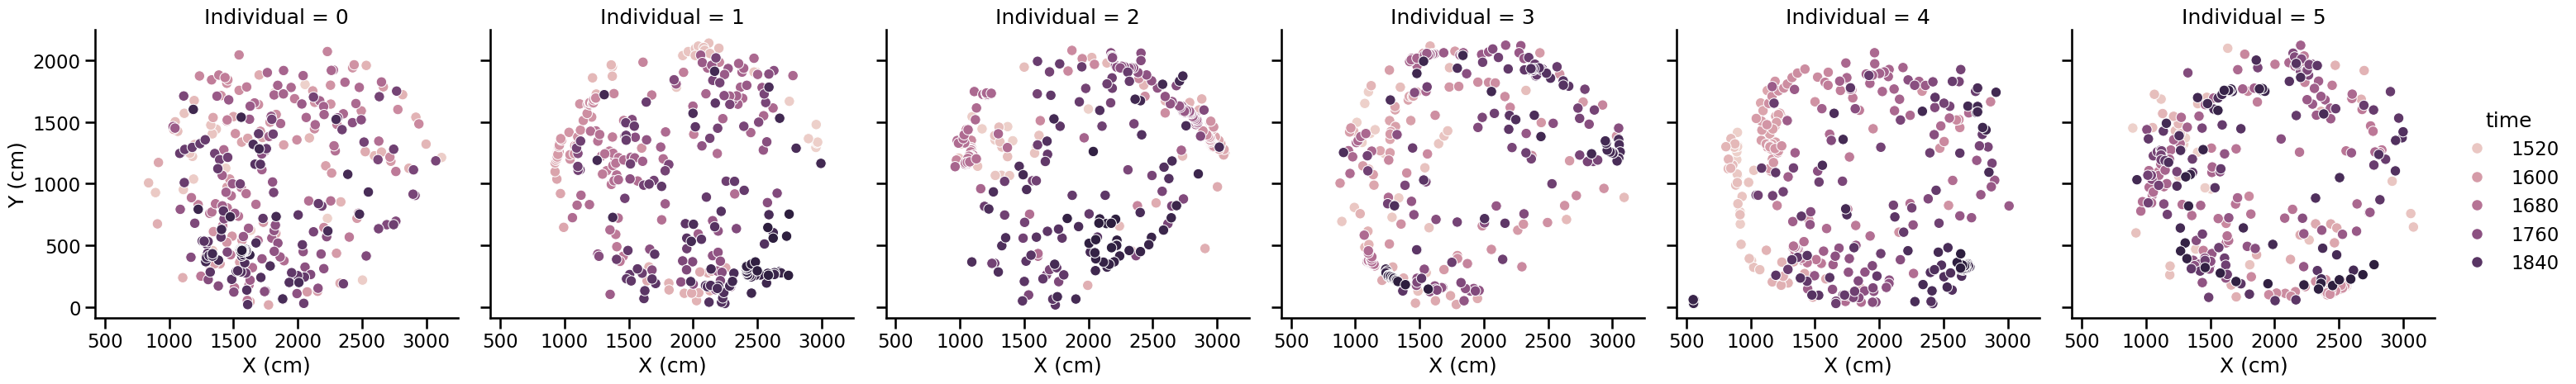

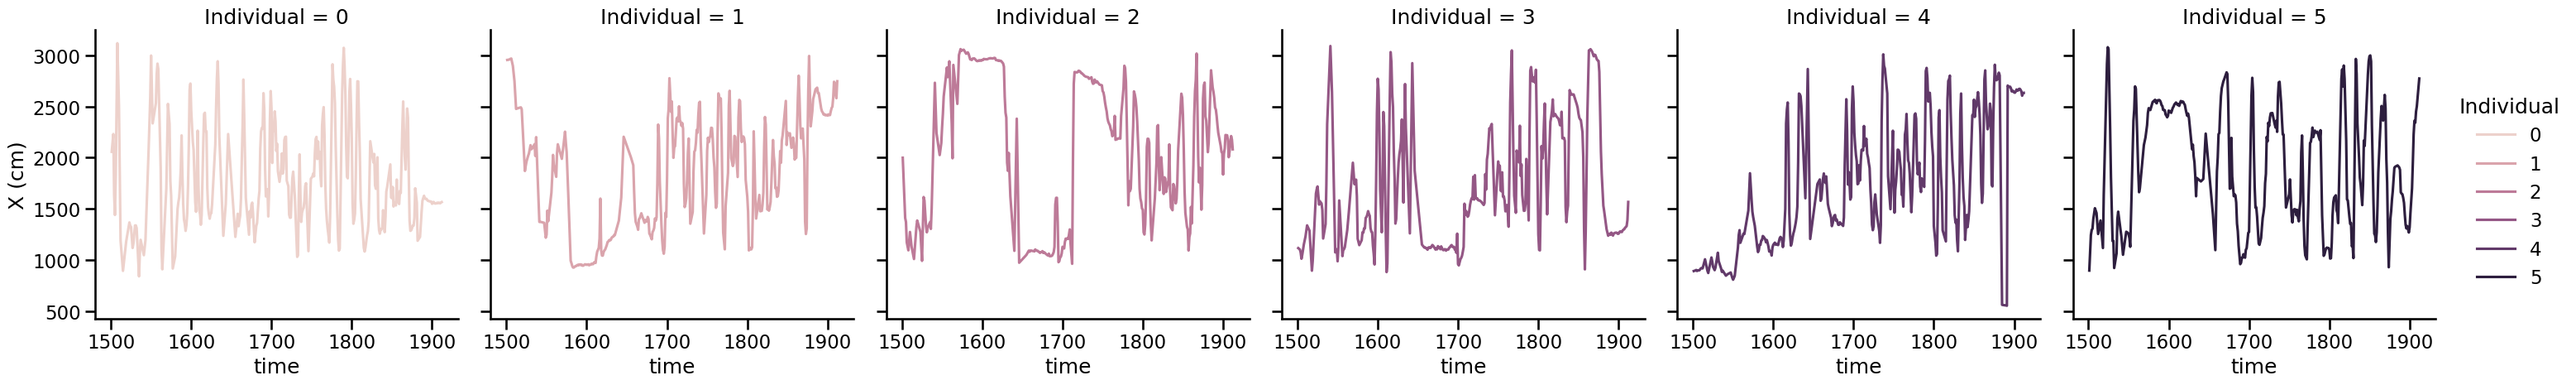

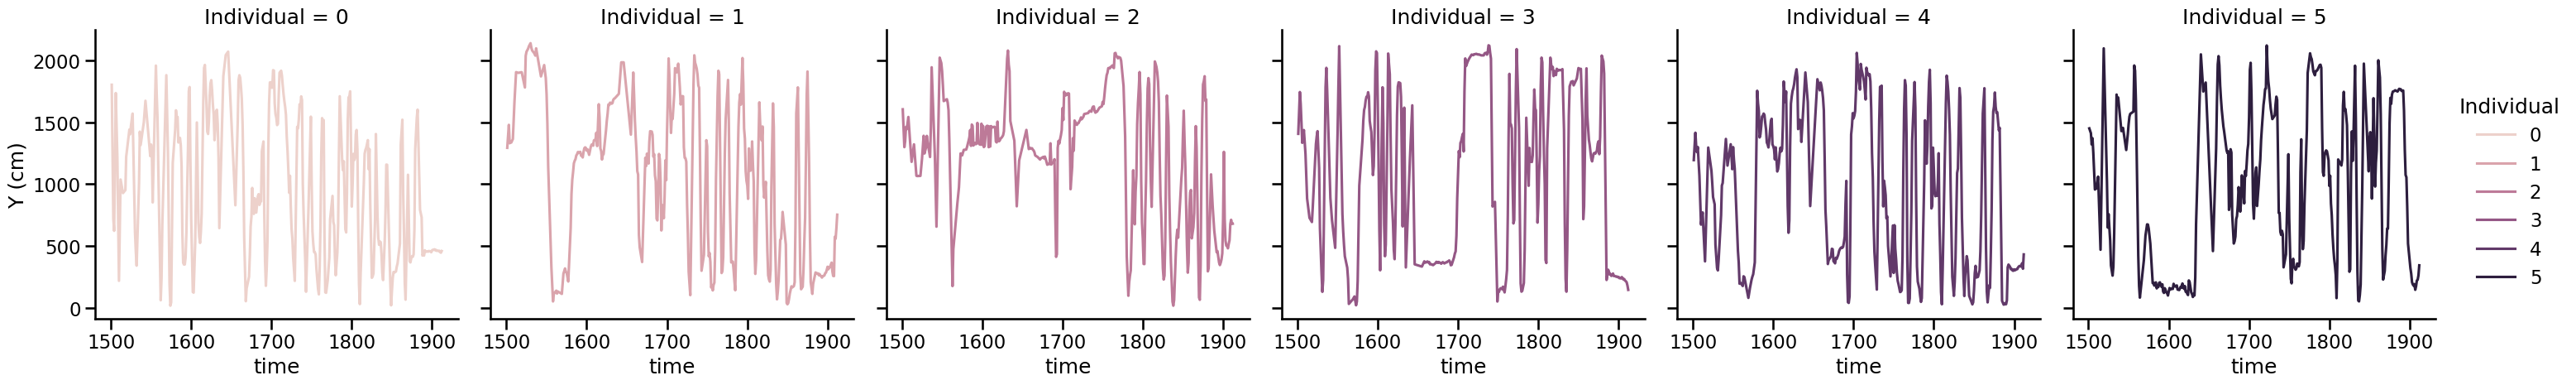

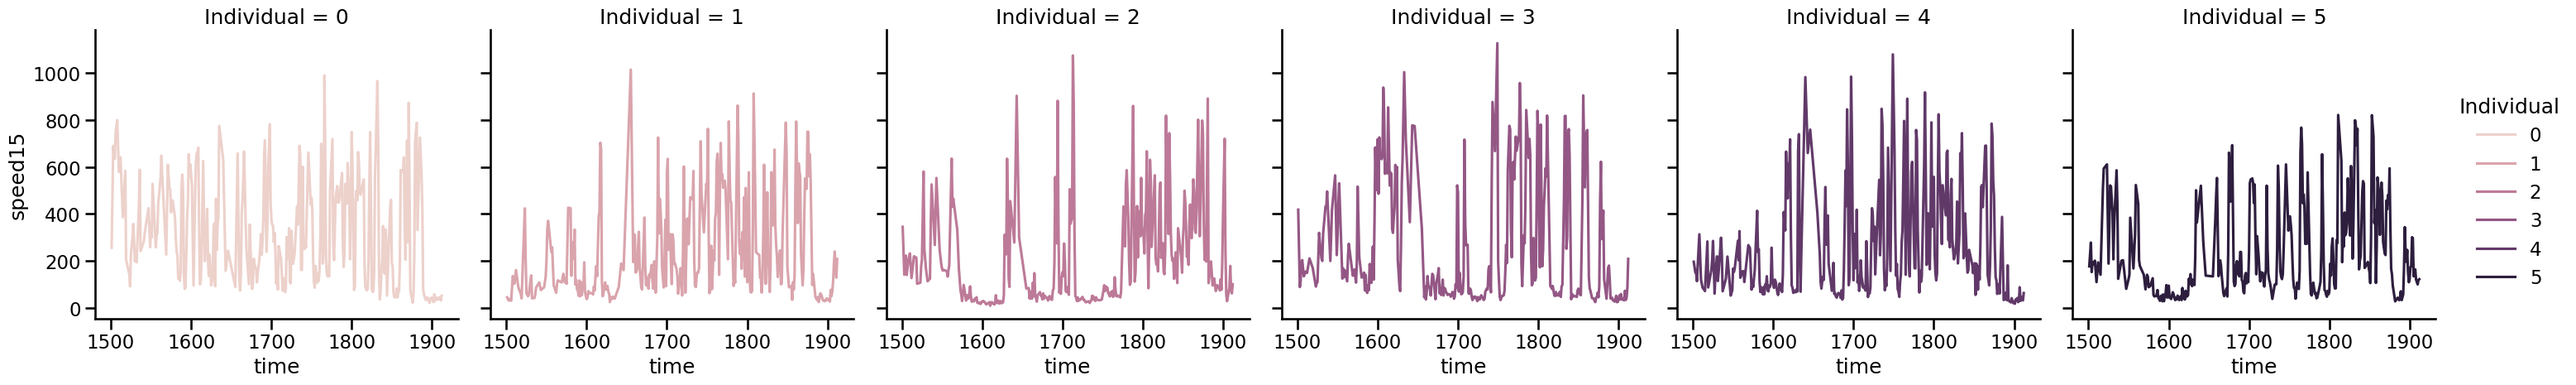

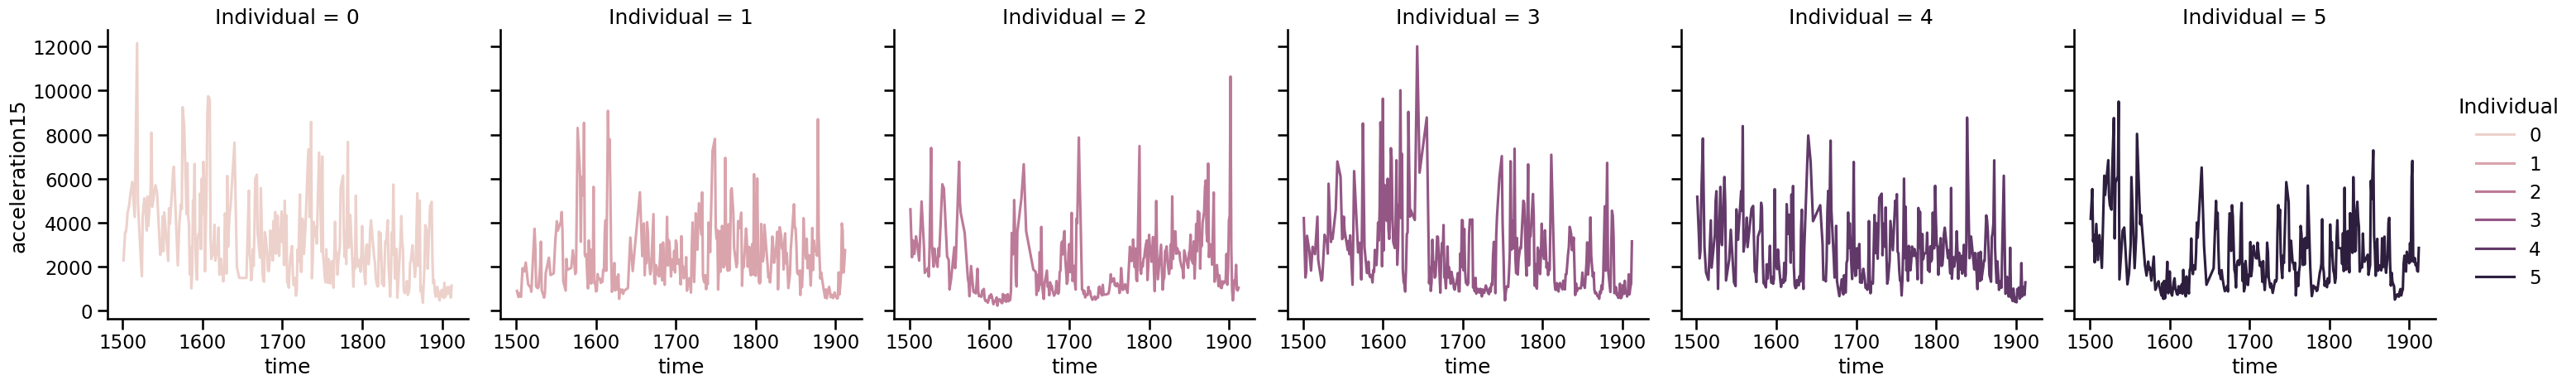

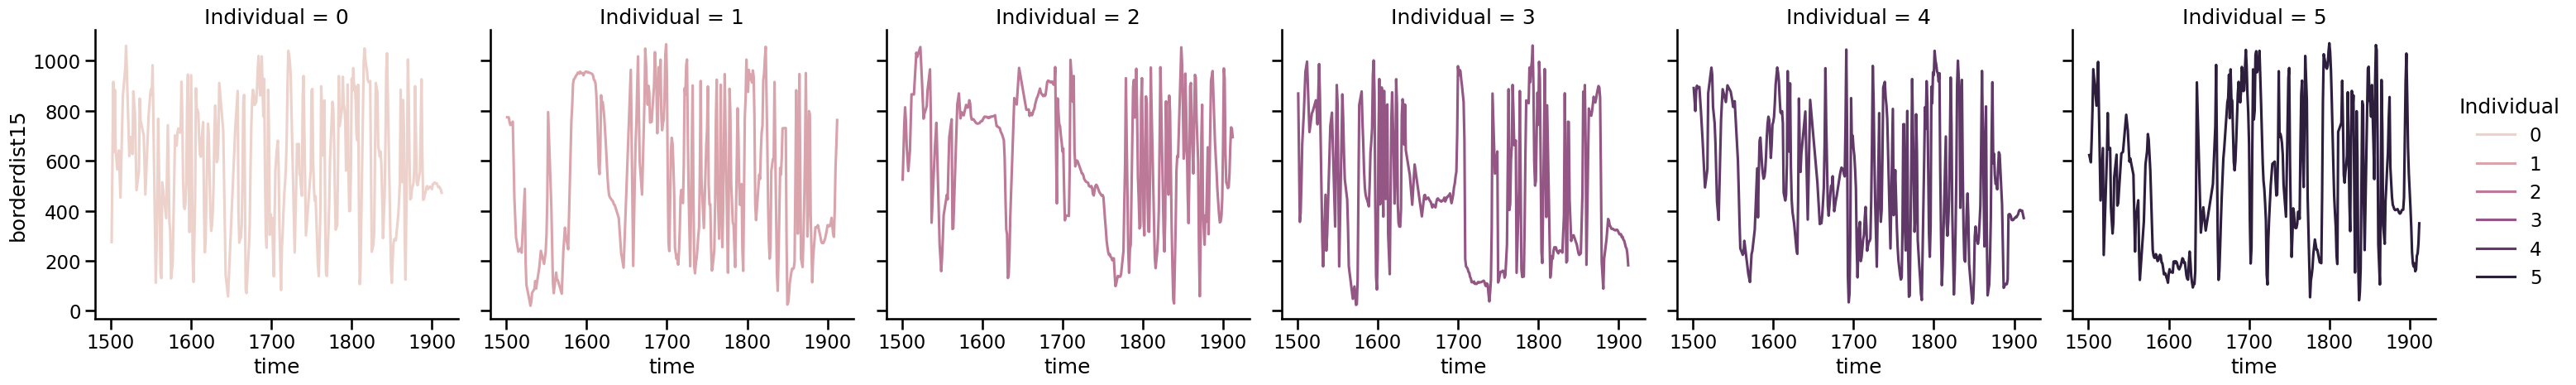

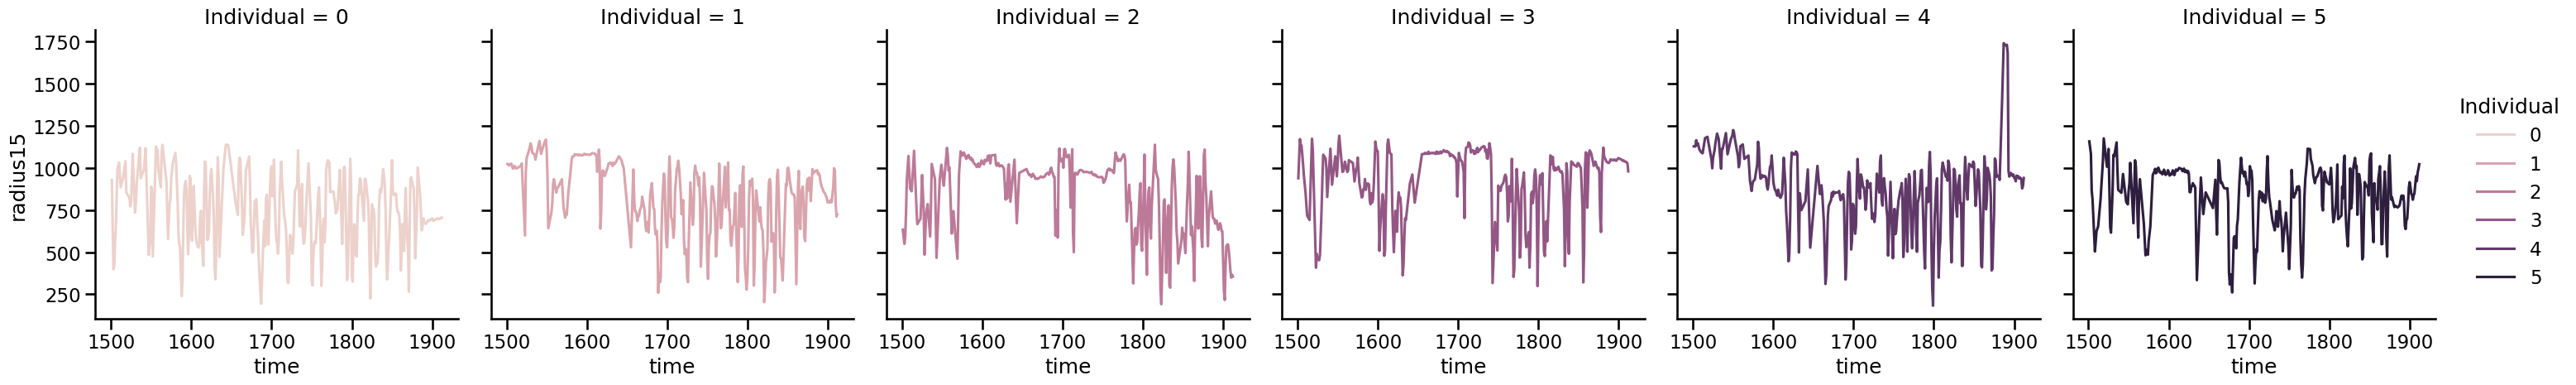

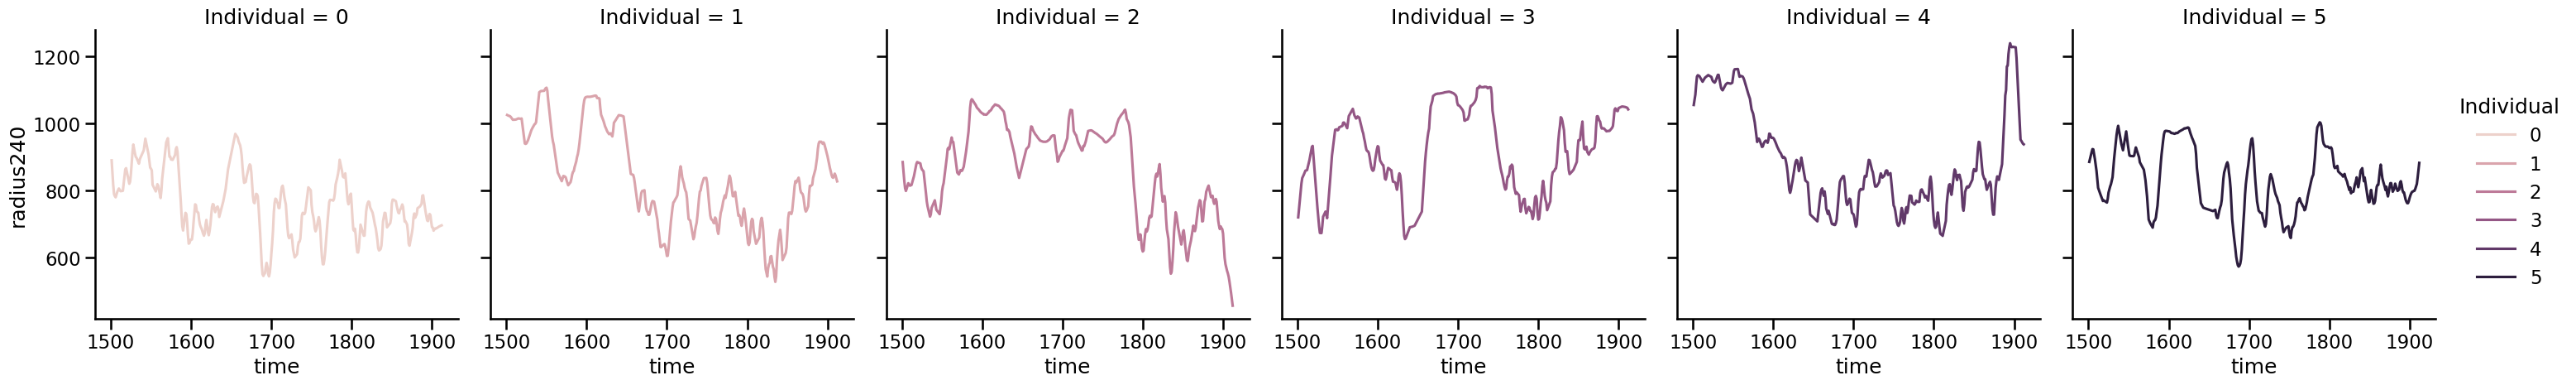

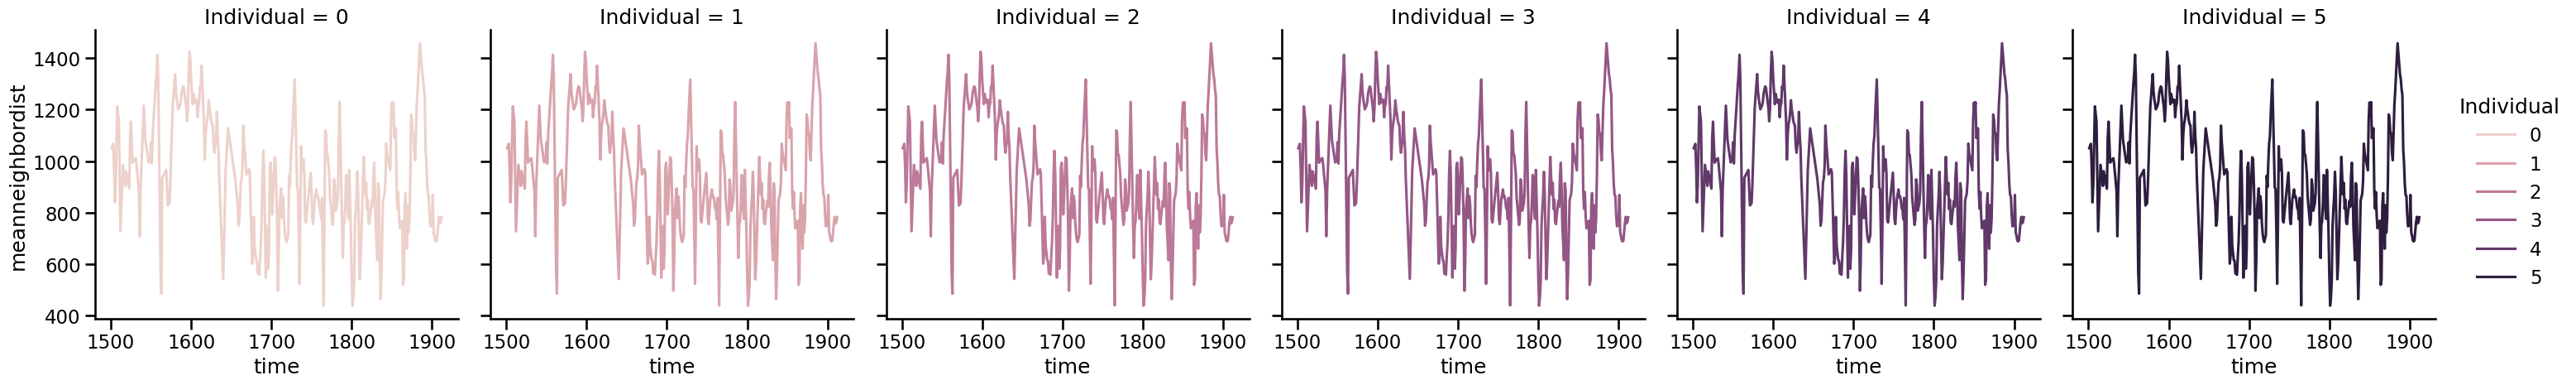

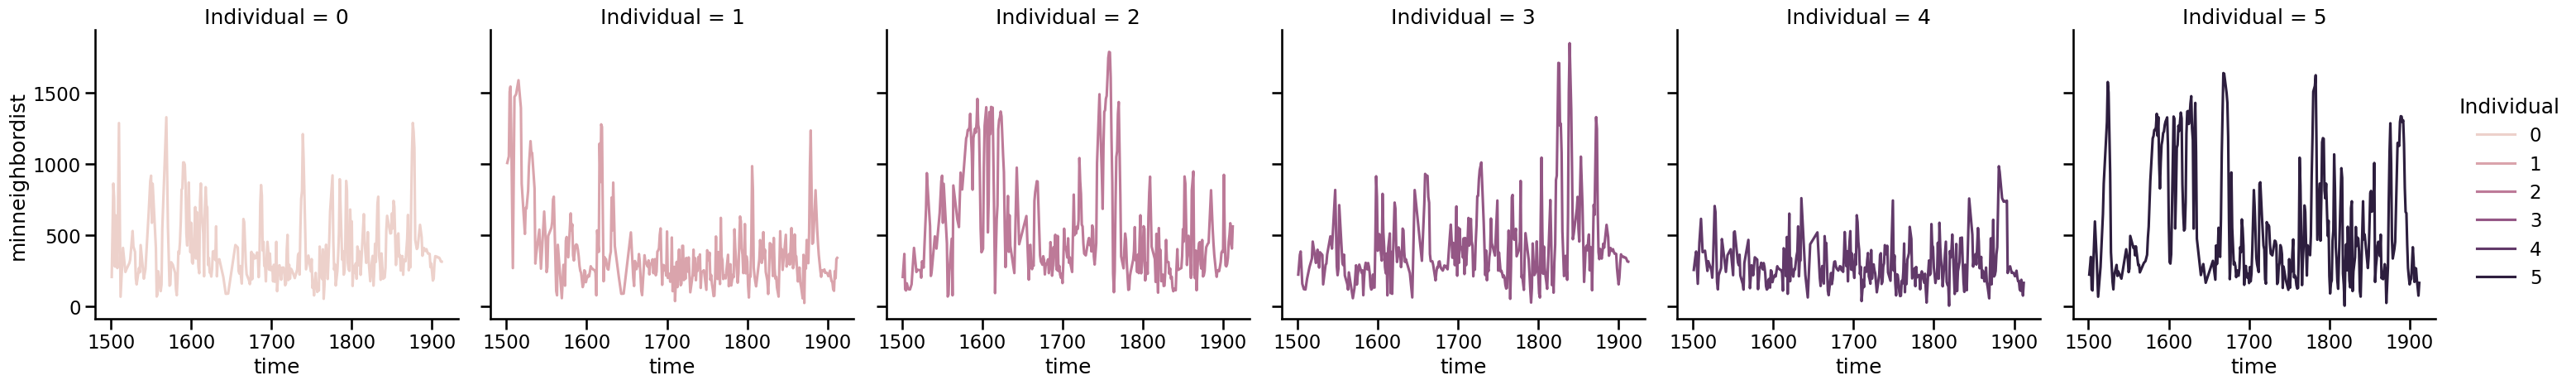

In [7]:
RIVER = "Skagit"
PH = 1
TRIAL = 8
VARIABLES = [
    "X (cm)",
    "Y (cm)",
    "speed15",
    "acceleration15",
    "borderdist15",
    "radius15",
    "radius240",
    "meanneighbordist",
    "minneighbordist",
]


one_video = df[
    (df["River"] == RIVER) &
    (df["pH"] == PH) &
    (df["Trial"] == TRIAL) &
    (df["time"] > 1500)
    # (df["time"] < 60 * 10)
    ]

sns.relplot(data=one_video, x="X (cm)", y="Y (cm)", hue="time", col="Individual")

for var in VARIABLES:
    p = sns.relplot(data=one_video, x="time", y=var, kind="line", hue="Individual", col="Individual", errorbar=None)

# Step 1. Qualitative analysis.

- One for each variable of interest (speed, mean distance btw. neighbors, radial pos)
- look at 3 different time series
- relaxation at the start (0 - ?)
- time series around the alarm (-? - +?)
- time series around the startle event (-? - +?)
- 6 different curves. average these. one for each Ph.
- or two panels.


In [2]:
VARIABLES = [
    "speed15",
    # "SPEED#wcentroid (cm/s)",
    "acceleration15",
    # "ACCELERATION#wcentroid (cm/s2)",
    # "X (cm)",
    # "Y (cm)",
    # "borderdist",
    "radius15",
    # "radius240",
    "meanneighbordist",
    "minneighbordist",
]

# First 10 minutes
first_10 = df[
    (df["time"] > 0) &
    (df["time"] < 60 * 10)]

# 5 minutes before and after skin extract injection.
skin_extract = df[
    (df["skin_extract_injection_time"] % 1.0 == 0) &
    (df["skin_extract_injection_time"] > -60 * 5) &
    (df["skin_extract_injection_time"] < 60 * 10)]

# 2 minutes before and 2 after the visual disturbance.
visual_disturbance = df[
    (df["visual_disturbance_time"] % 1.0 == 0) &
    (df["visual_disturbance_time"] > -60 * 2) &
    (df["visual_disturbance_time"] < 60 * 2)]

for _df, title, time_var in [
    # (first_10, "FIRST 10 MINUTES", "time"),
    (skin_extract, "BEFORE AND AFTER SKIN EXTRACT INJECTION",  "skin_extract_injection_time"),
    # (visual_disturbance, "BEFORE AND AFTER VISUAL DISTURBANCE", "visual_disturbance_time")]:
]:


    for i, var in enumerate(VARIABLES):
        p = sns.relplot(data=_df, x=time_var, y=var, kind="line", col="River", hue="pH", errorbar=None)
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)


NameError: name 'df' is not defined

# Step 2. Histogram of variables (speed, mean distance btw neighbors, radial pos)

- first 5 minutes
- 10 minutes leading up to the pheromone
- 3 minutes after the pheromone
- 30 seconds after the startle



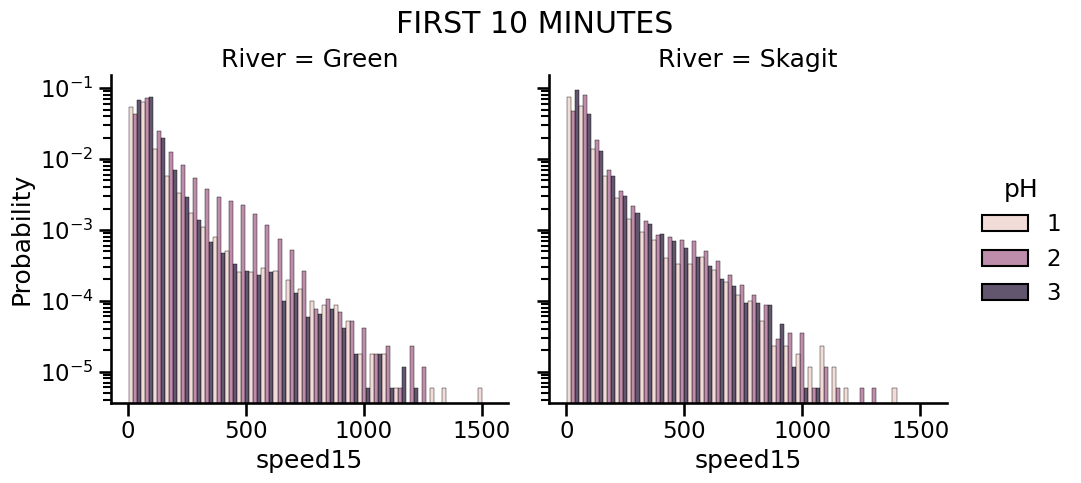

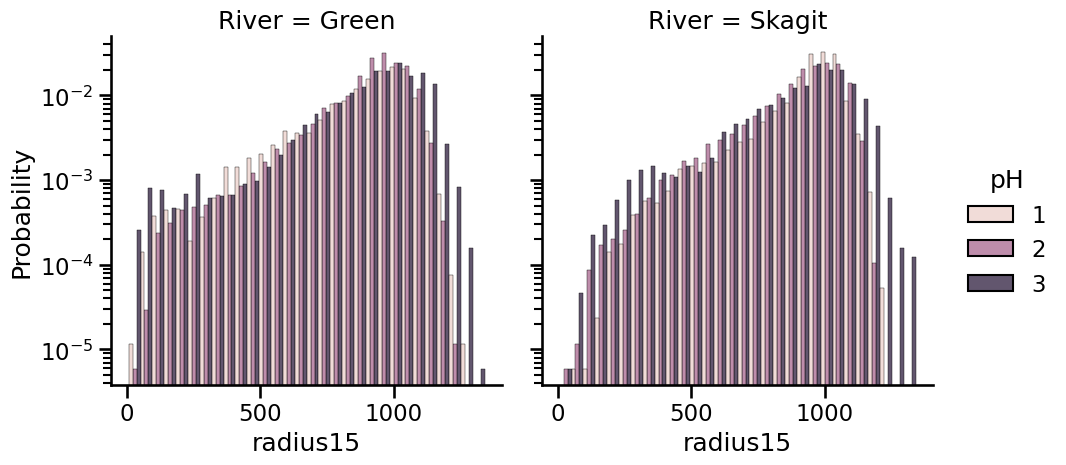

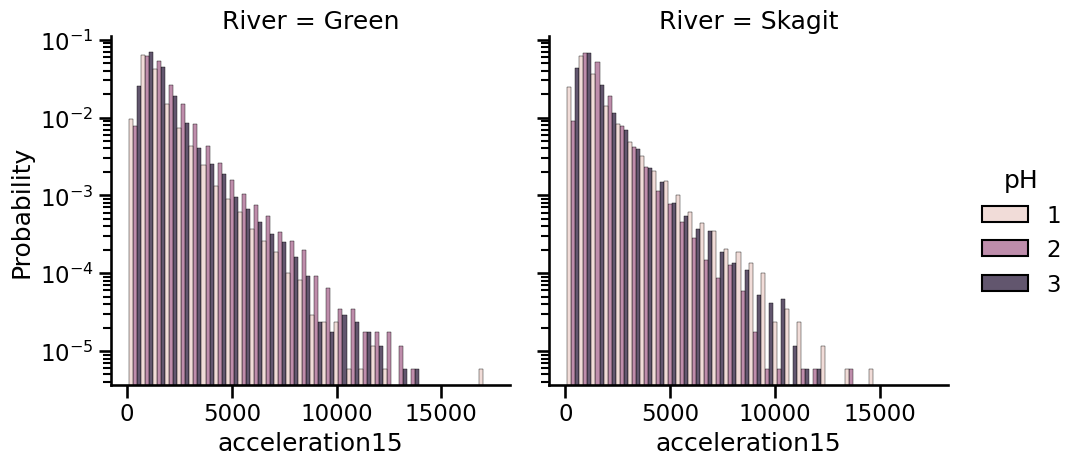

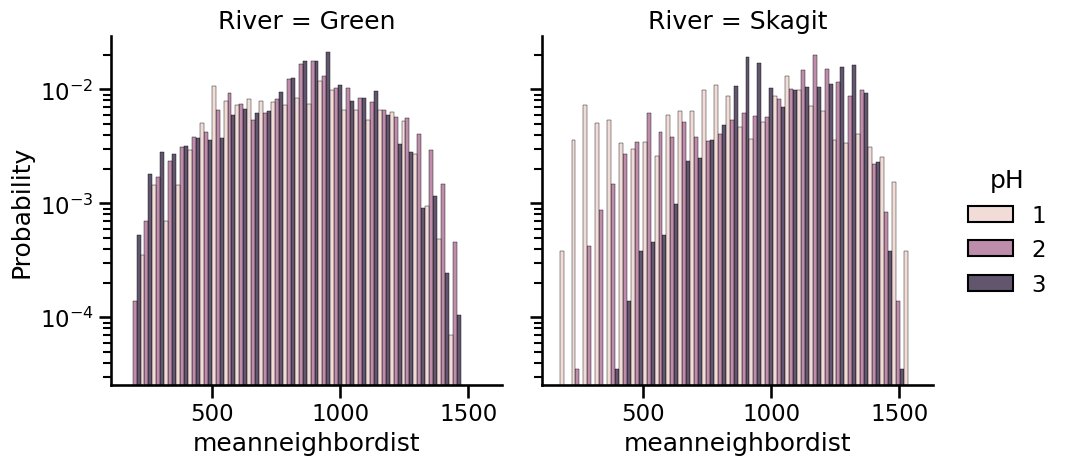

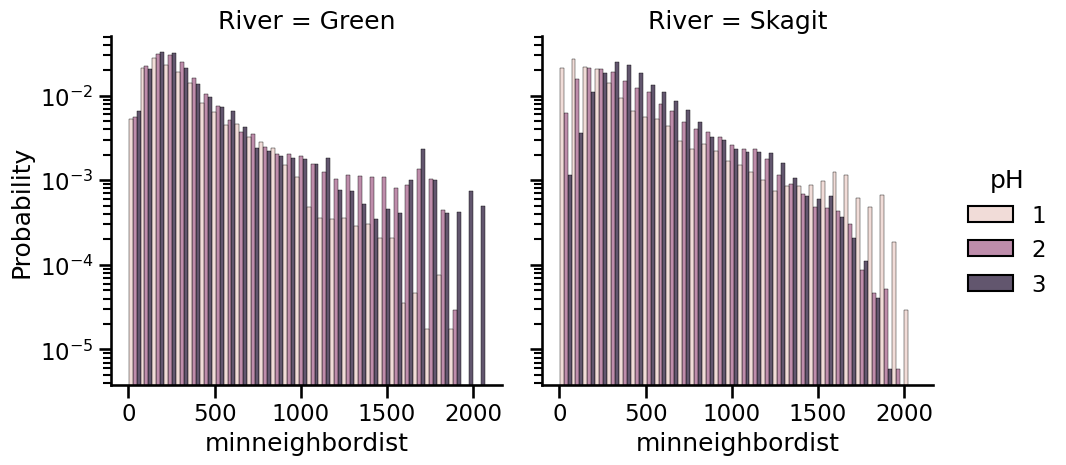

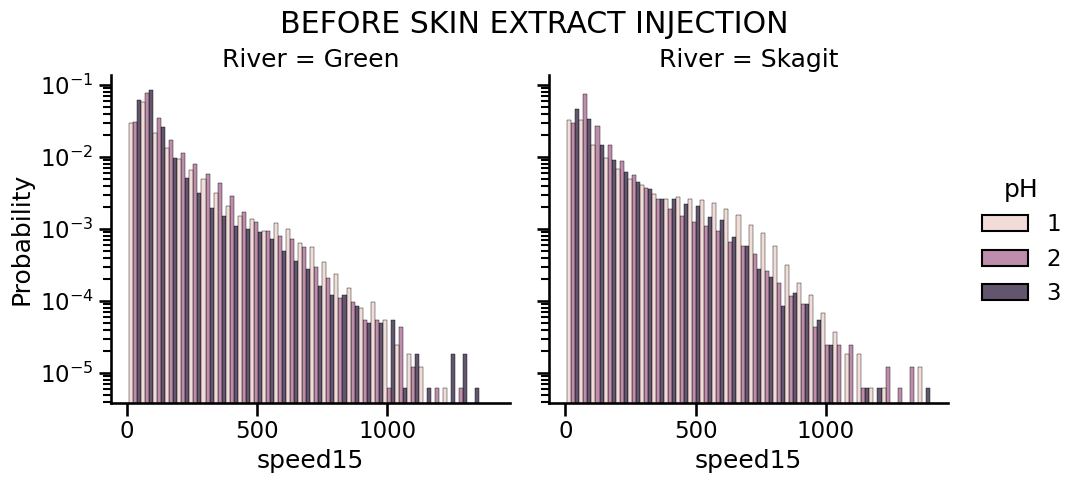

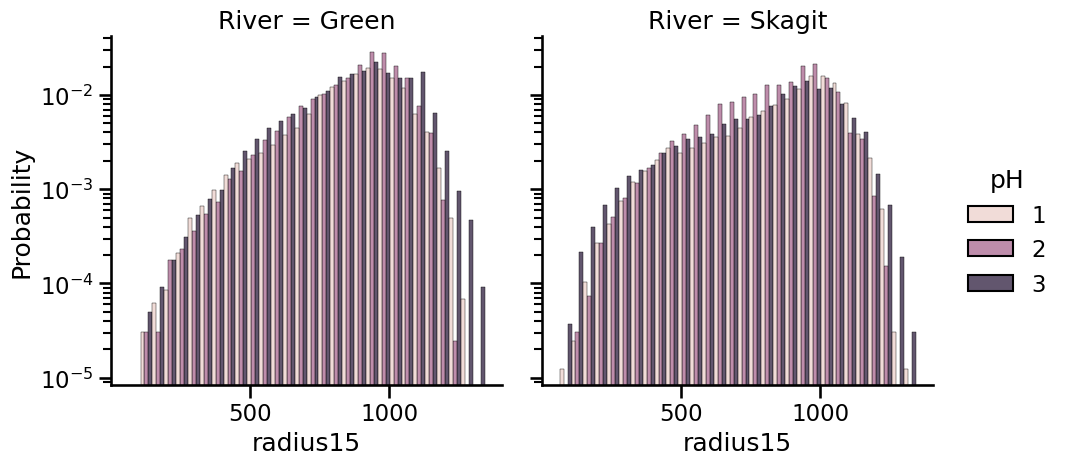

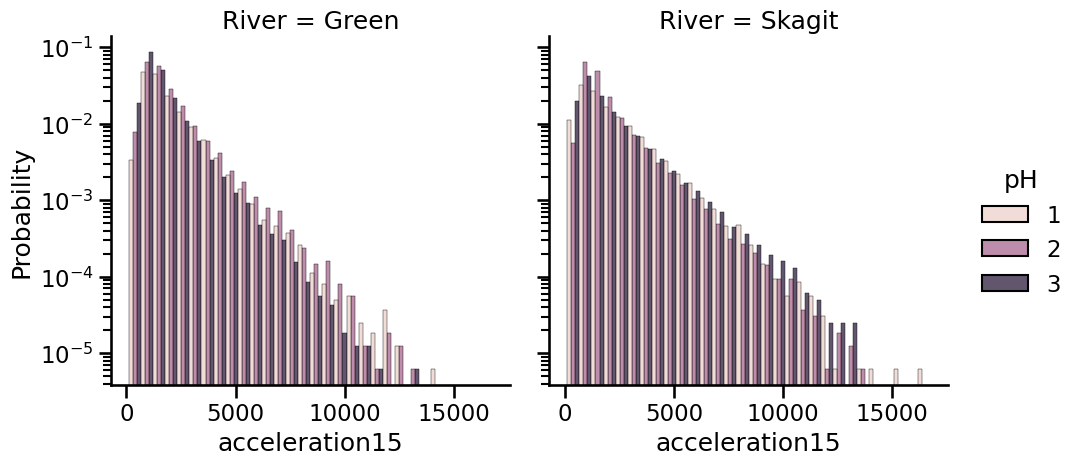

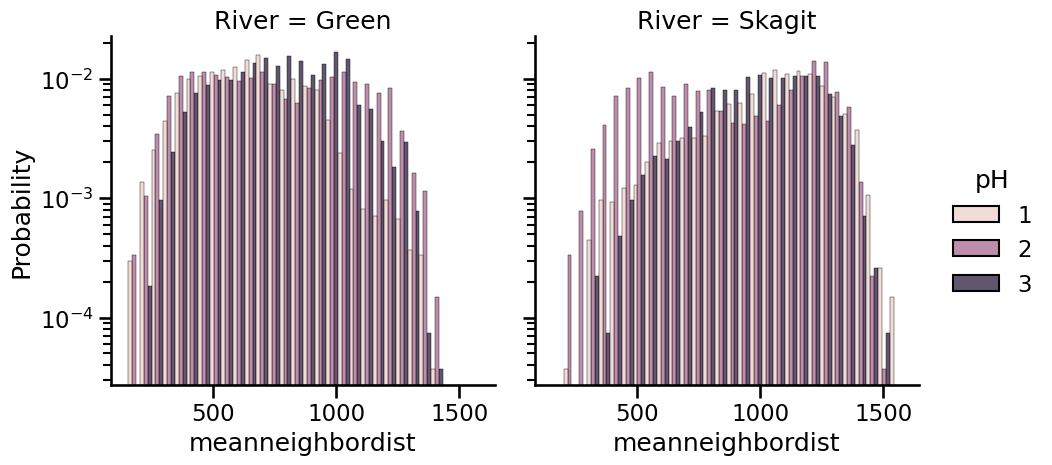

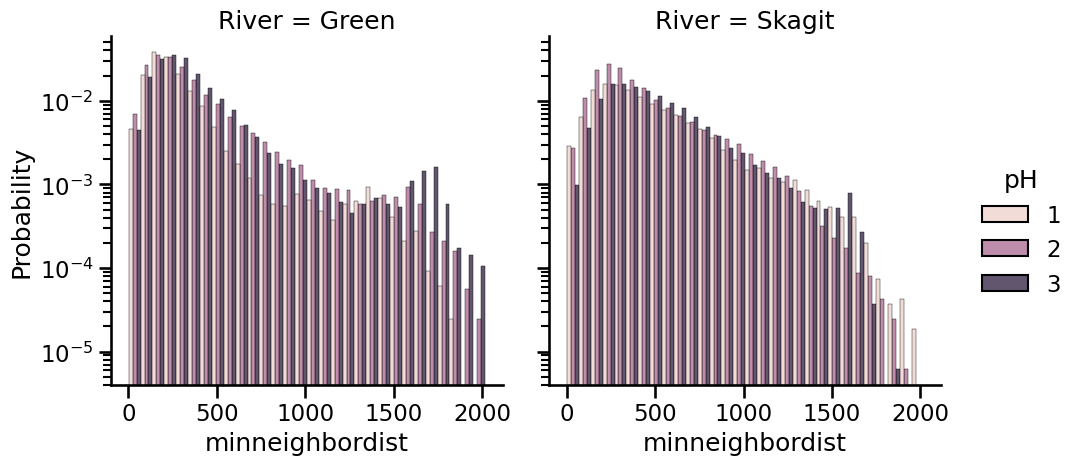

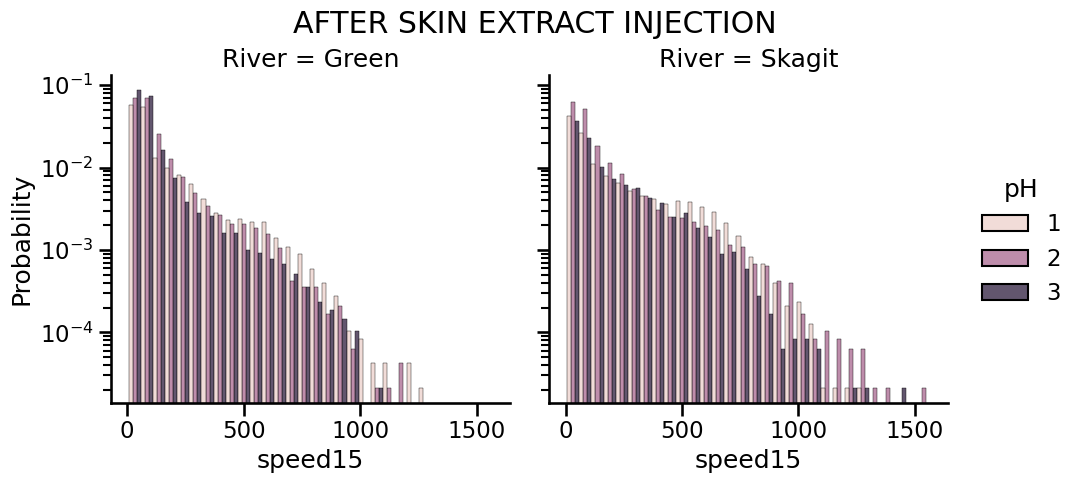

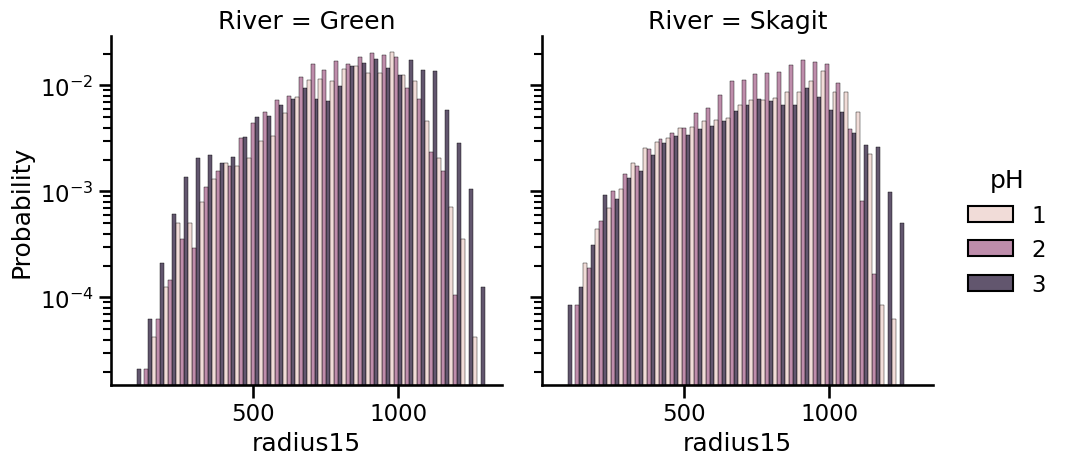

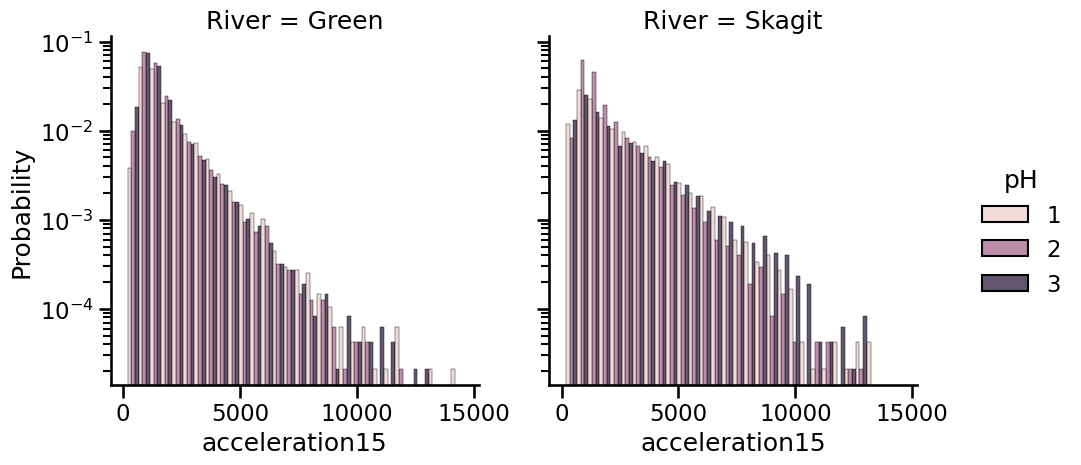

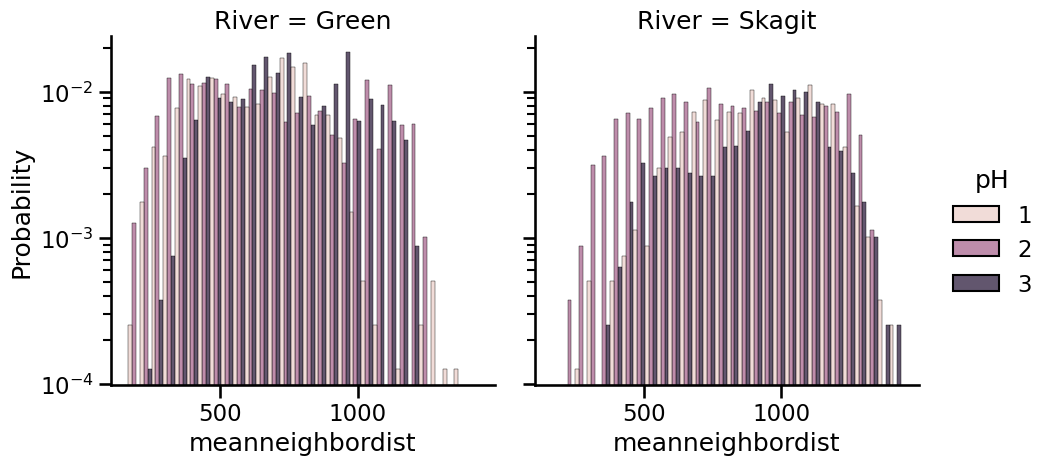

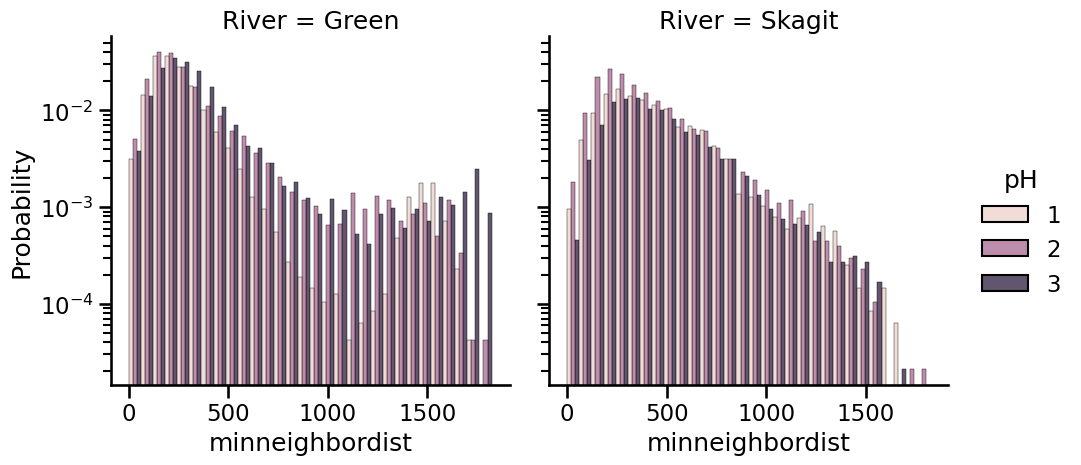

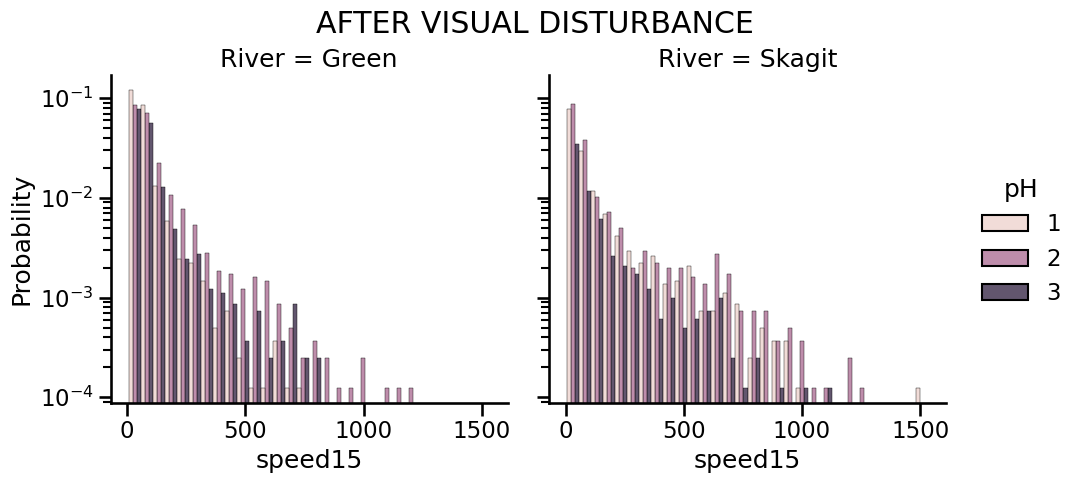

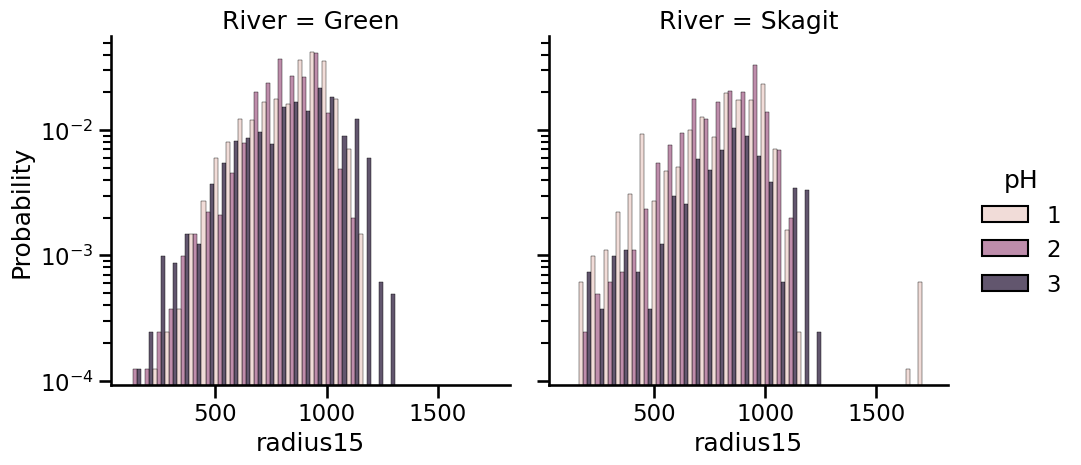

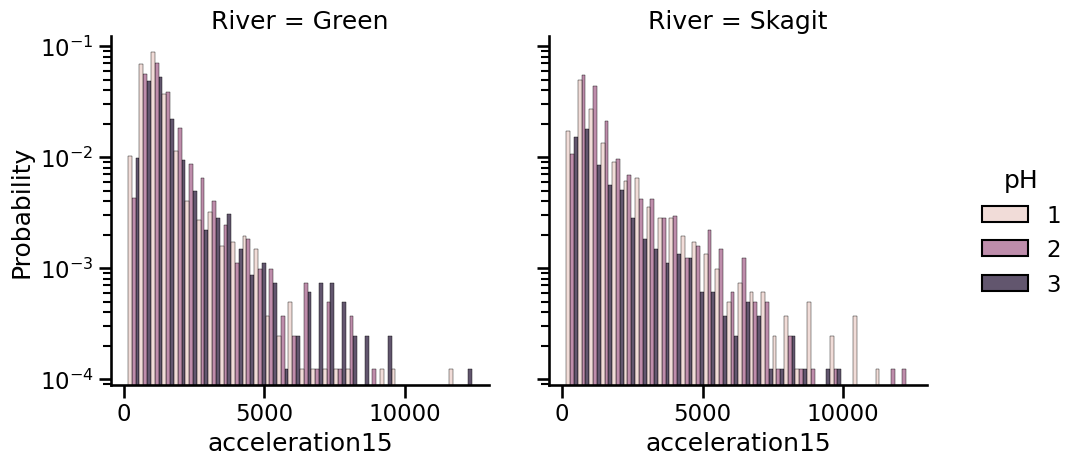

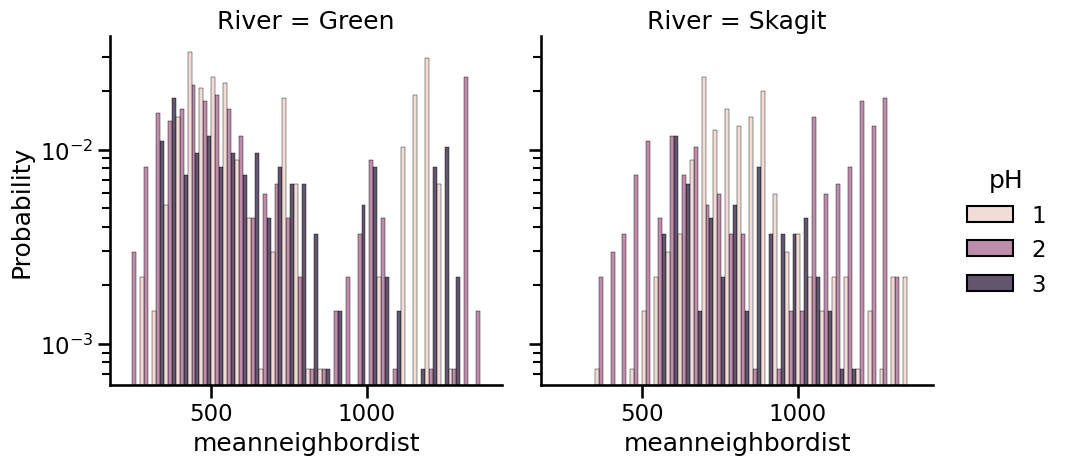

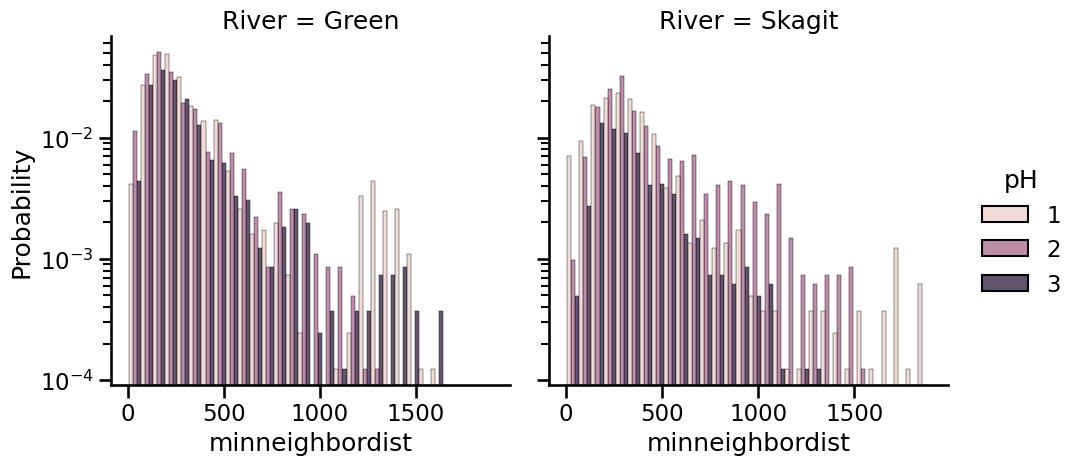

In [9]:
VARIABLES = [
    "speed15",
    "radius15",
    "acceleration15",
    "meanneighbordist",
    "minneighbordist"
]

first_ten = df[
    (df["time"] <= 10 * 60)
]

before_skin_extract = df[
    (df["skin_extract_injection_time"] >= -10 * 60) &
    (df["skin_extract_injection_time"] <= 0 * 60)
]

after_skin_extract = df[
    (df["skin_extract_injection_time"] >= 0 * 60) &
    (df["skin_extract_injection_time"] <= 3 * 60)
    ]

after_visual_disturbance = df[
    (df["visual_disturbance_time"] >= 0 * 60) &
    (df["visual_disturbance_time"] <= 2 * 60)
]


for _df, title in [
    (first_10, "FIRST 10 MINUTES"),
    (before_skin_extract, "BEFORE SKIN EXTRACT INJECTION"),
    (after_skin_extract, "AFTER SKIN EXTRACT INJECTION"),
    (after_visual_disturbance, "AFTER VISUAL DISTURBANCE")]:


    for i, var in enumerate(VARIABLES):
        p = sns.displot(
            data=_df, x=var, col="River", hue="pH",
            kind="hist", multiple="dodge",
            stat="probability",
            bins=30,
            # (x_scale, y_scale)
            # log_scale=(False, True),
        )
        p.set(yscale='log')
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)




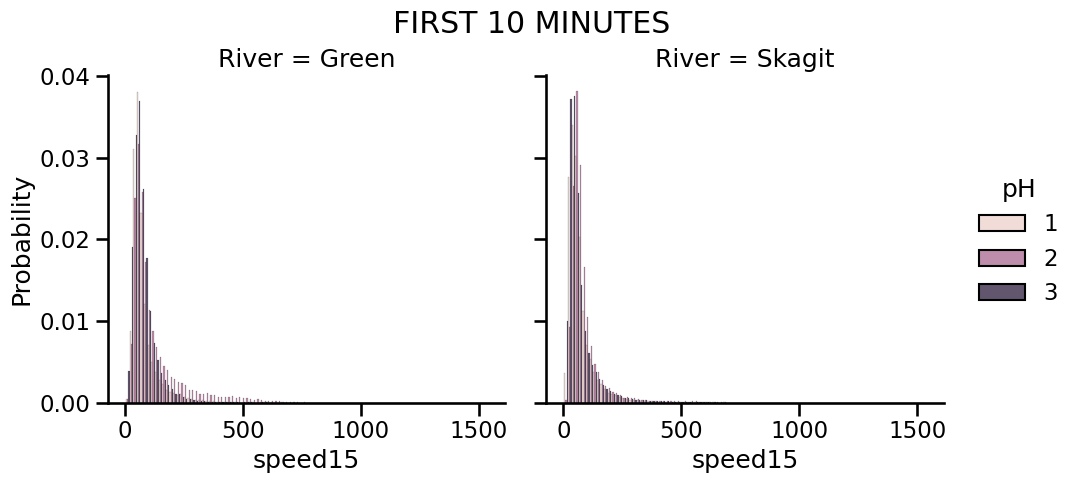

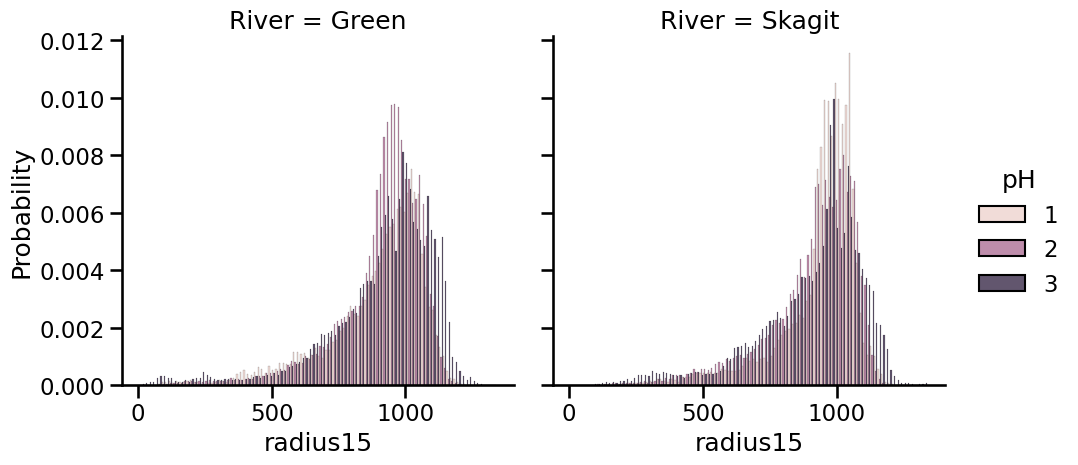

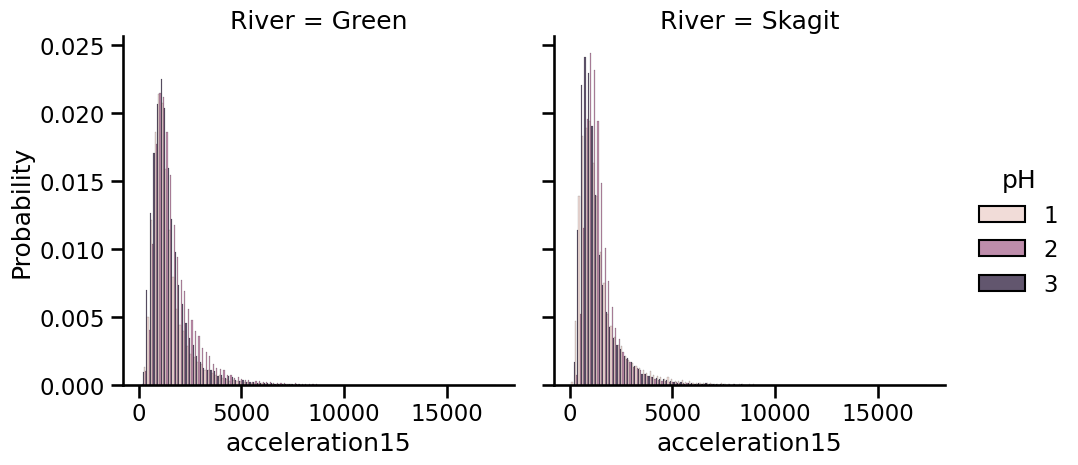

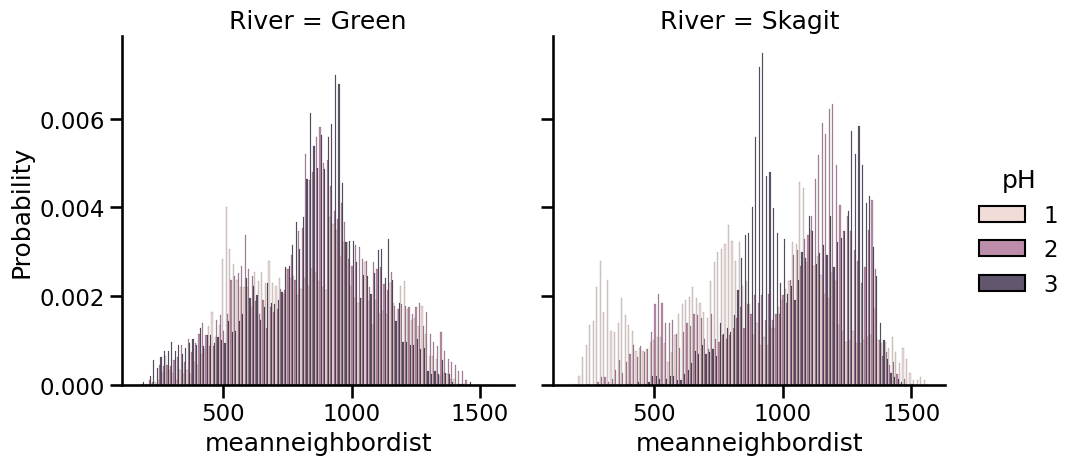

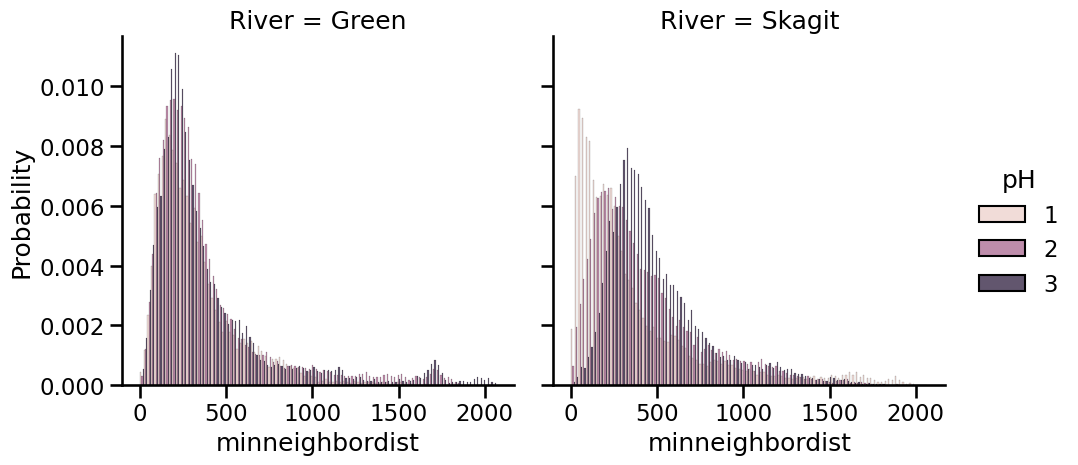

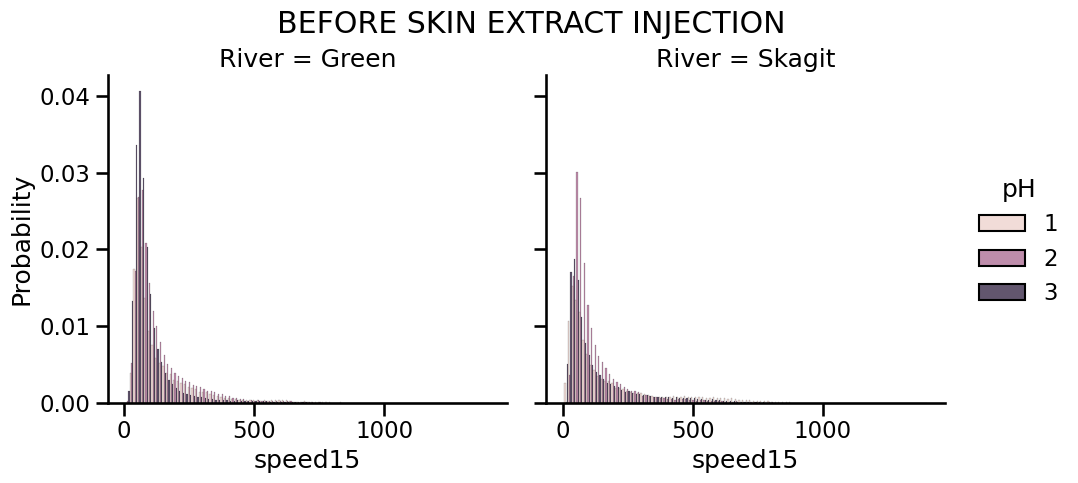

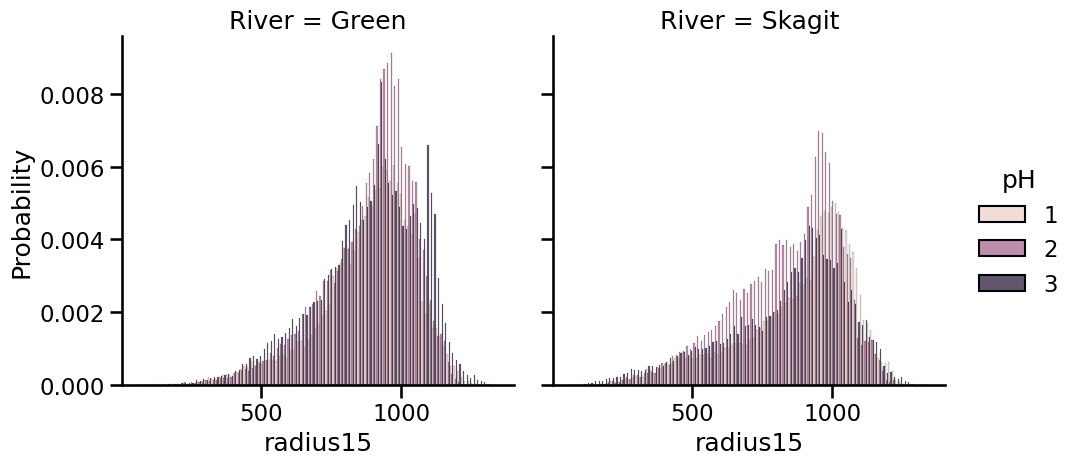

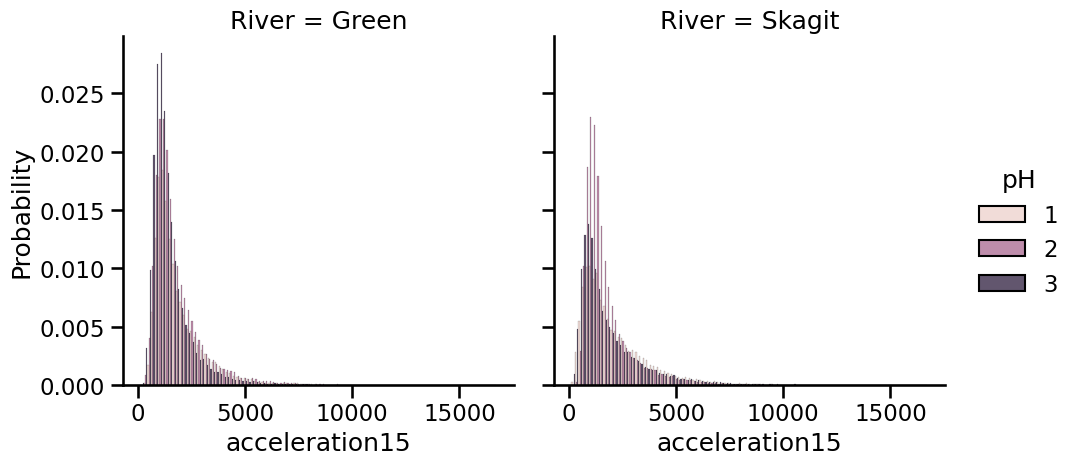

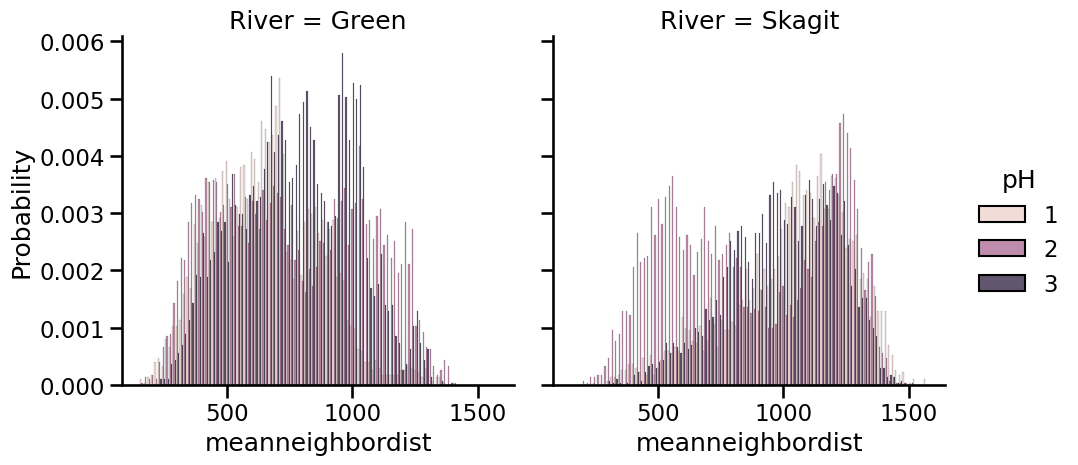

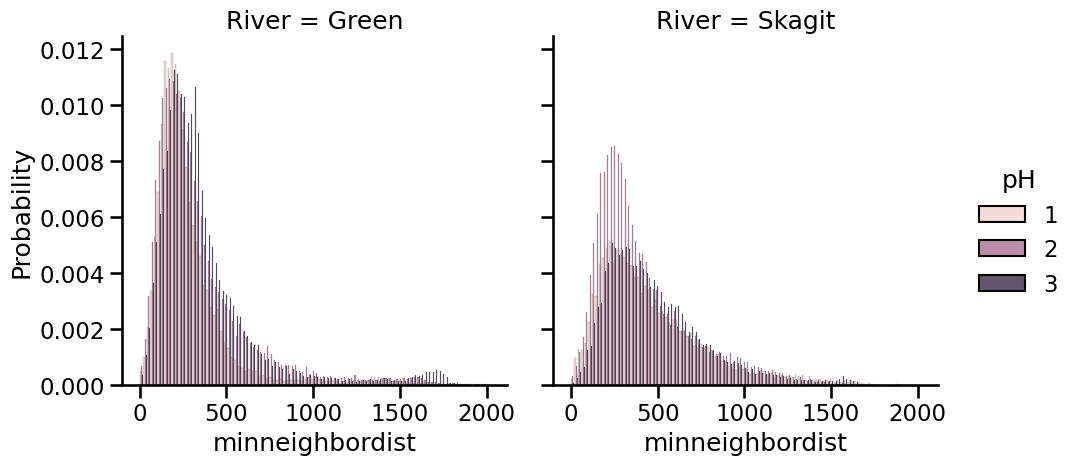

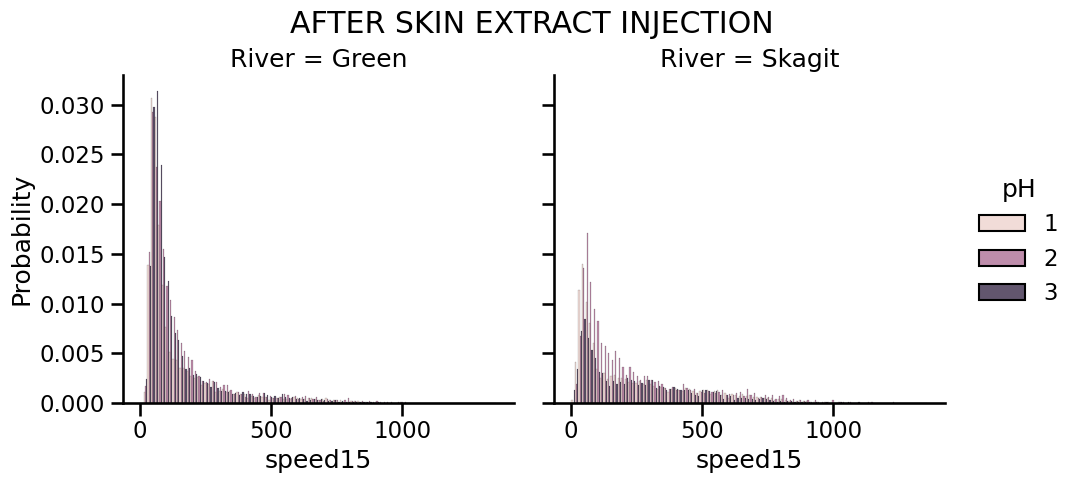

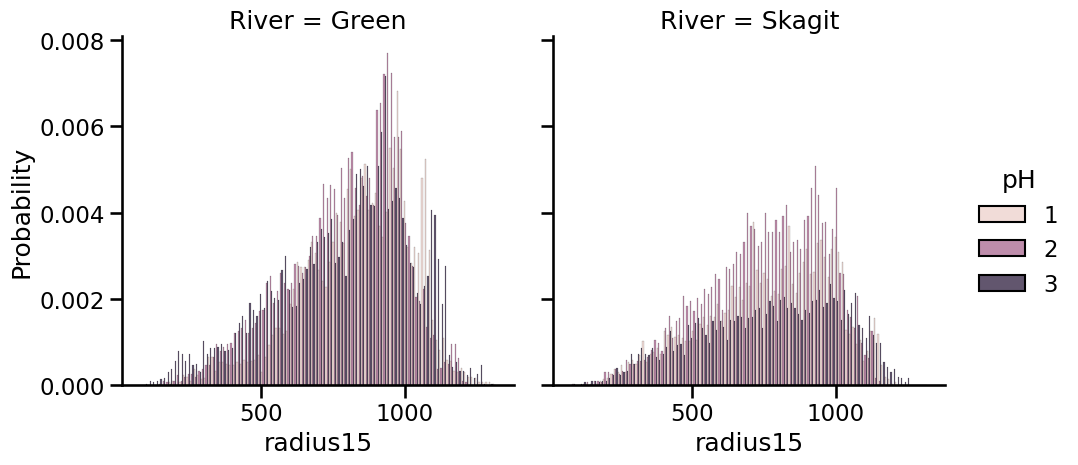

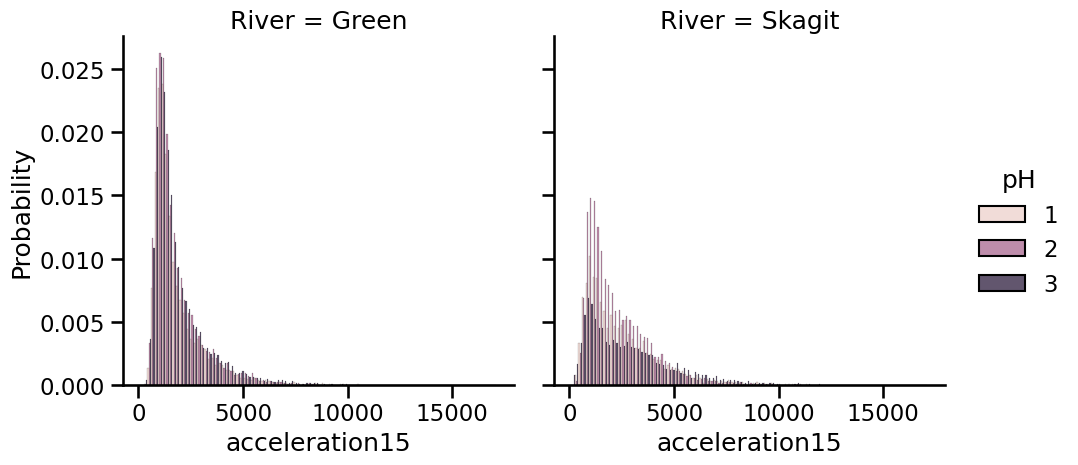

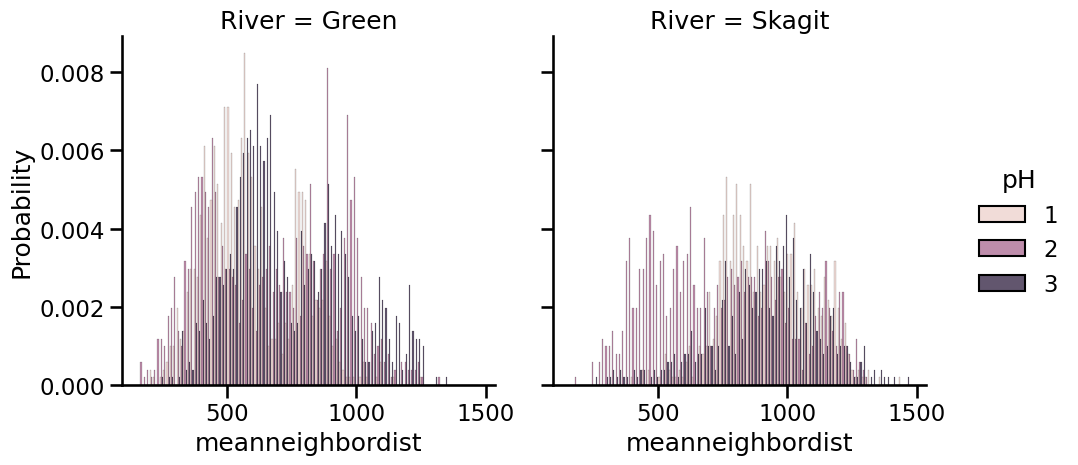

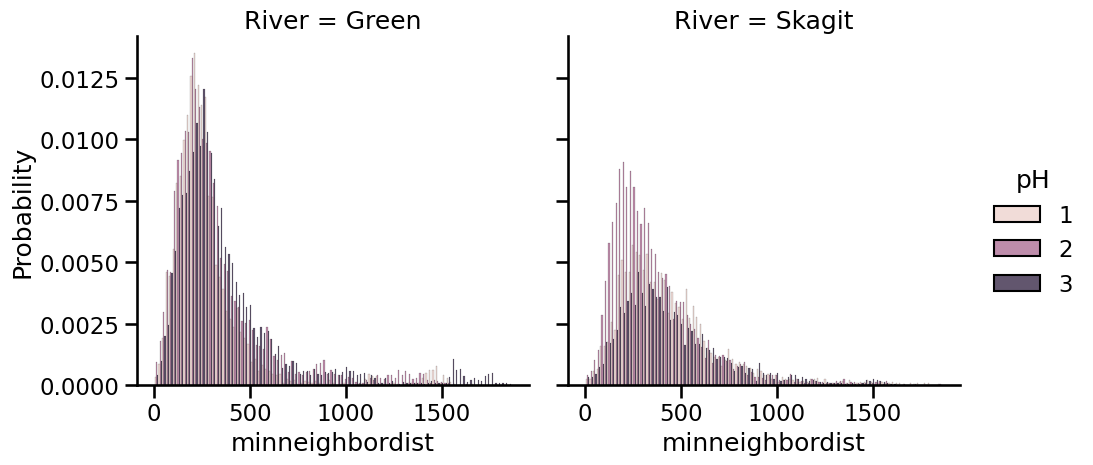

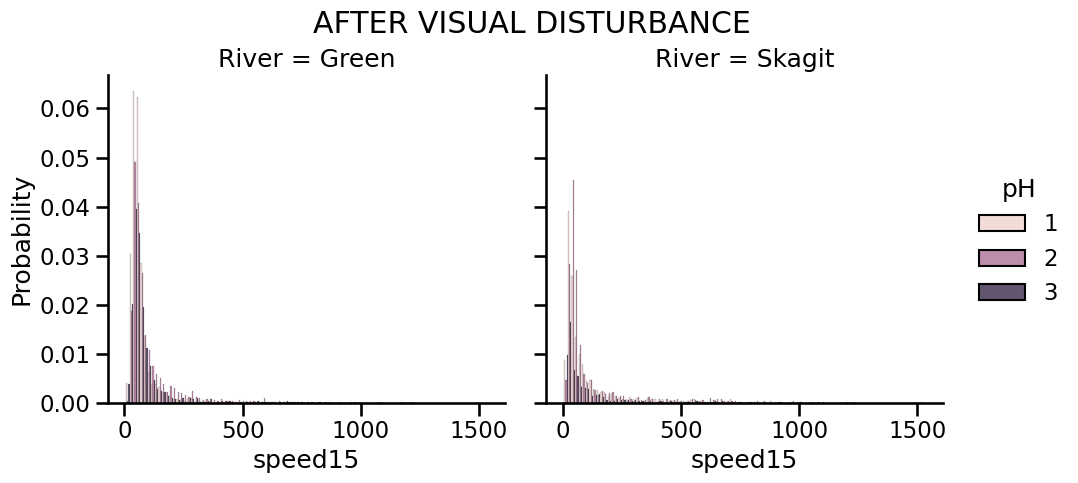

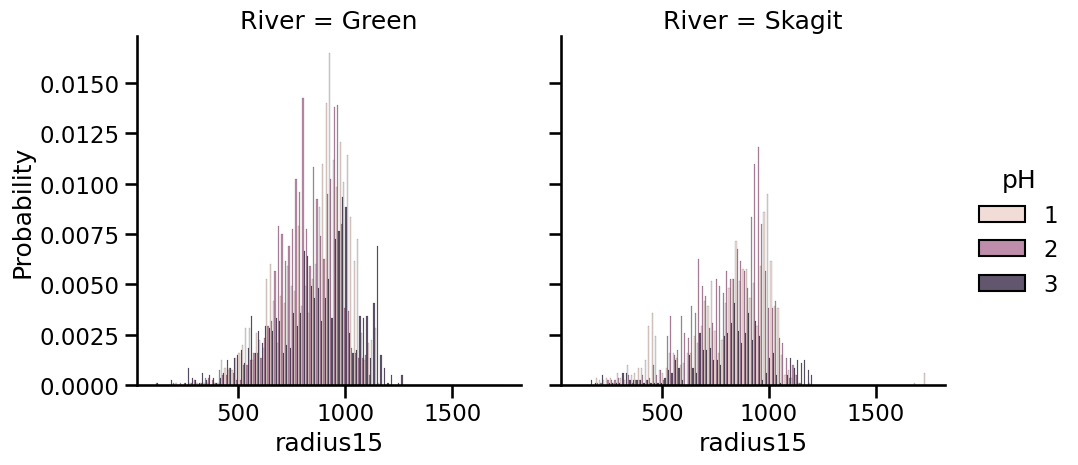

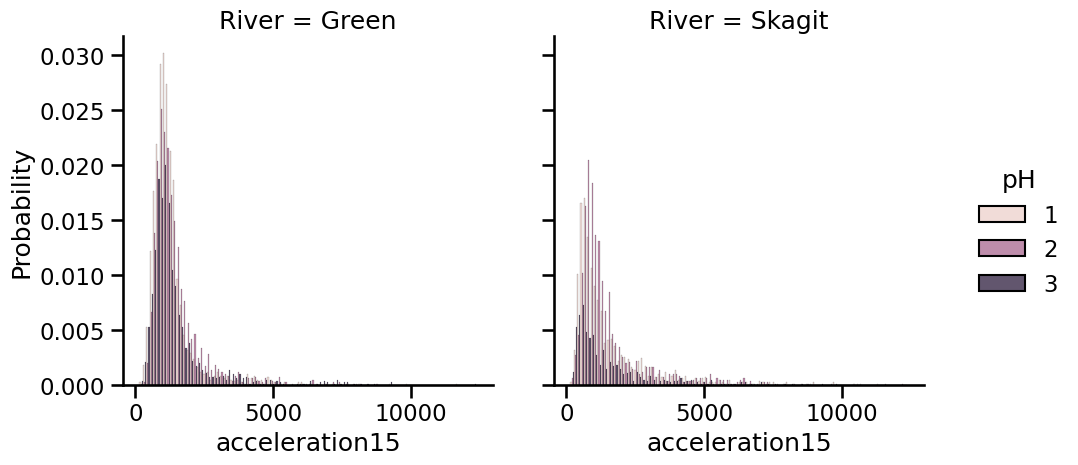

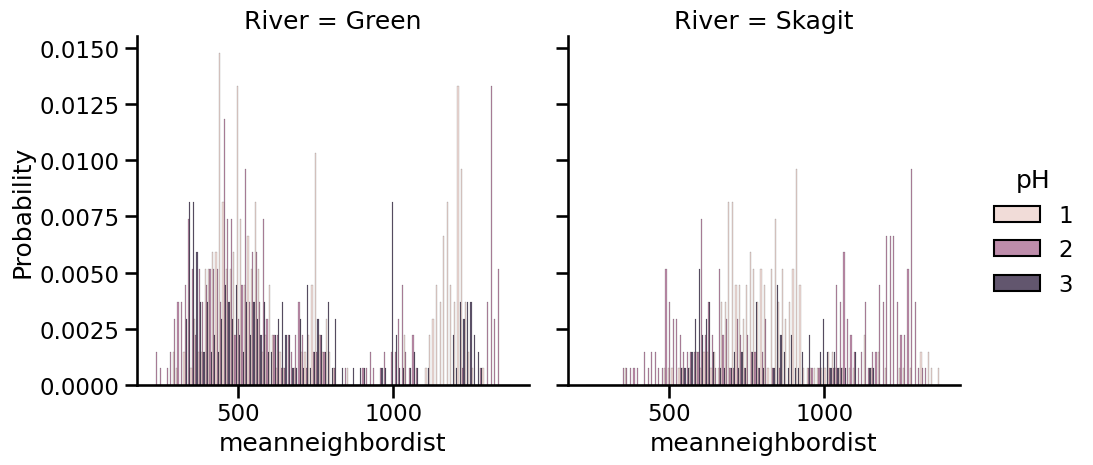

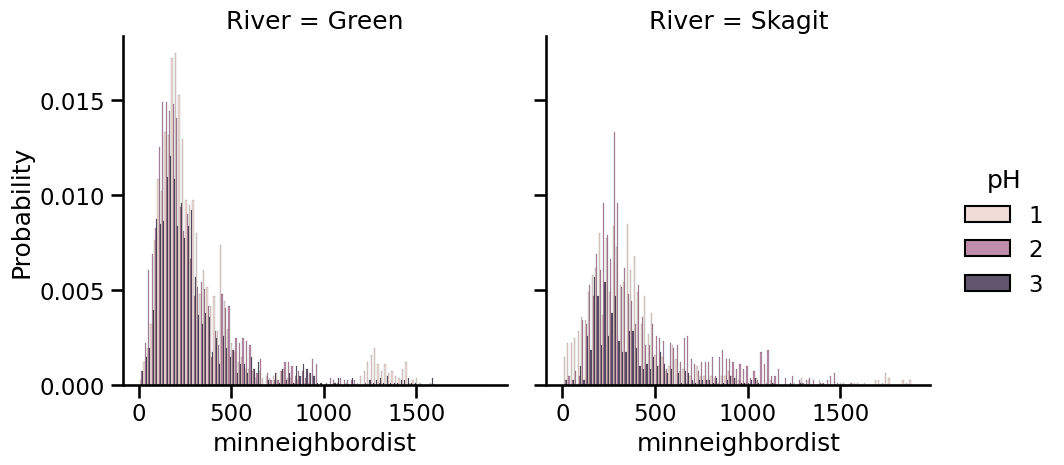

In [10]:
VARIABLES = [
    "speed15",
    "radius15",
    "acceleration15",
    "meanneighbordist",
    "minneighbordist"
]

first_ten = df[
    (df["time"] <= 10 * 60)
]

before_skin_extract = df[
    (df["skin_extract_injection_time"] >= -10 * 60) &
    (df["skin_extract_injection_time"] <= 0 * 60)
]

after_skin_extract = df[
    (df["skin_extract_injection_time"] >= 3 * 60) &
    (df["skin_extract_injection_time"] <= 5 * 60)
    ]

after_visual_disturbance = df[
    (df["visual_disturbance_time"] >= 0 * 60) &
    (df["visual_disturbance_time"] <= 2 * 60)
]


for _df, title in [
    (first_ten, "FIRST 10 MINUTES"),
    (before_skin_extract, "BEFORE SKIN EXTRACT INJECTION"),
    (after_skin_extract, "AFTER SKIN EXTRACT INJECTION"),
    (after_visual_disturbance, "AFTER VISUAL DISTURBANCE")]:


    for i, var in enumerate(VARIABLES):
        p = sns.displot(
            data=_df, x=var, col="River", hue="pH",
            kind="hist", multiple="dodge",
            stat="probability",
            bins=100,
            log_scale=(False, False),
        )
        # p.set_yscale('log')
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)




# Step 3. Some sort of difference around the pheromone introduction & around the startle

- delta of the histograms between before & after timing
- one for pheromones, one for the startle
- or a histogram of the deltas of the means.
- some way to quantify how the distribution is changing.


In [11]:
# Computes these intervals for before/after skin_extract time
data = []
# Groups by trial: all fish go into the mean.
GROUPBY_VARS = ["River", "pH", "Trial"]
DELTA_VARS = ["speed15", "acceleration15", "radius15",  "meanneighbordist", "minneighbordist"]


def compute_deltas(df, col_name, interval):
    for group_name, group_df in df.groupby(GROUPBY_VARS):
        before_df = group_df[
            (group_df[col_name] > -1 * interval) &
            (group_df[col_name] < 0)]
        after_df = group_df[
            (group_df[col_name] >= 0) &
            (group_df[col_name] < interval)]
    
        # This is all the column values as a list.
        row = list(group_name)
    
        for delta_var in DELTA_VARS:
            delta = after_df[delta_var].replace([np.inf, -np.inf], np.nan).mean() - before_df[delta_var].replace([np.inf, -np.inf], np.nan).mean()
            row.append(delta)
            
    
        data.append(row)
    
    deltas_df = pd.DataFrame(data, columns=GROUPBY_VARS + [delta_var + "_delta" for delta_var in DELTA_VARS])
    return deltas_df

skin_extract_deltas = compute_deltas(df, "skin_extract_injection_time", 5 * 60)

visual_disturbance_deltas = compute_deltas(df, "visual_disturbance_time", 2 * 60)

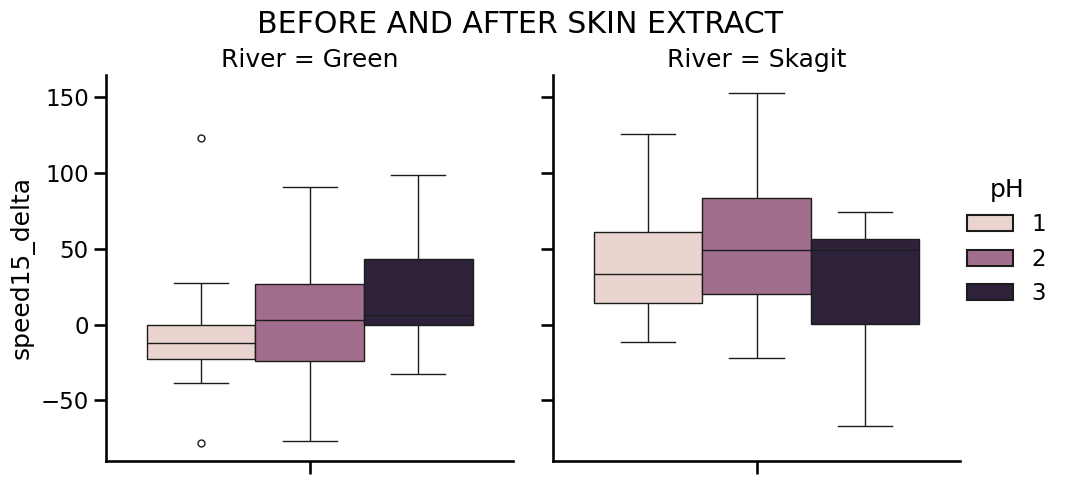

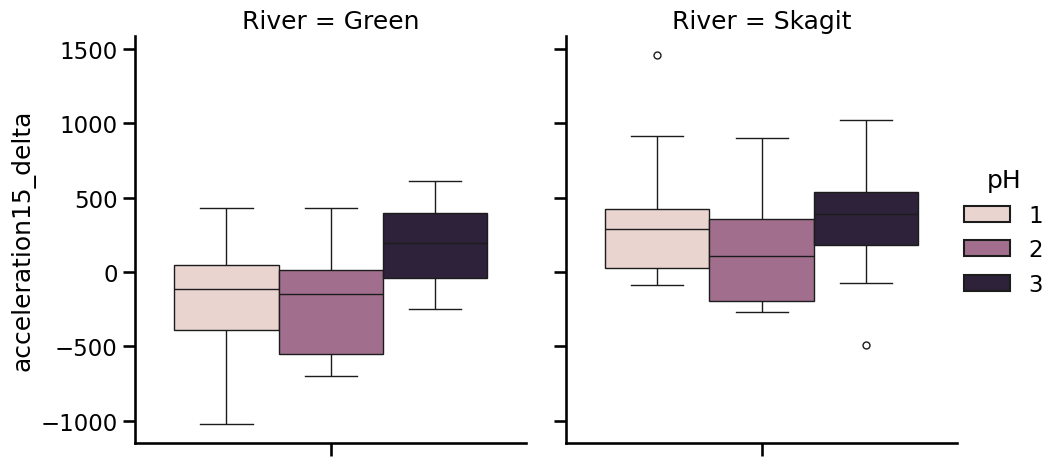

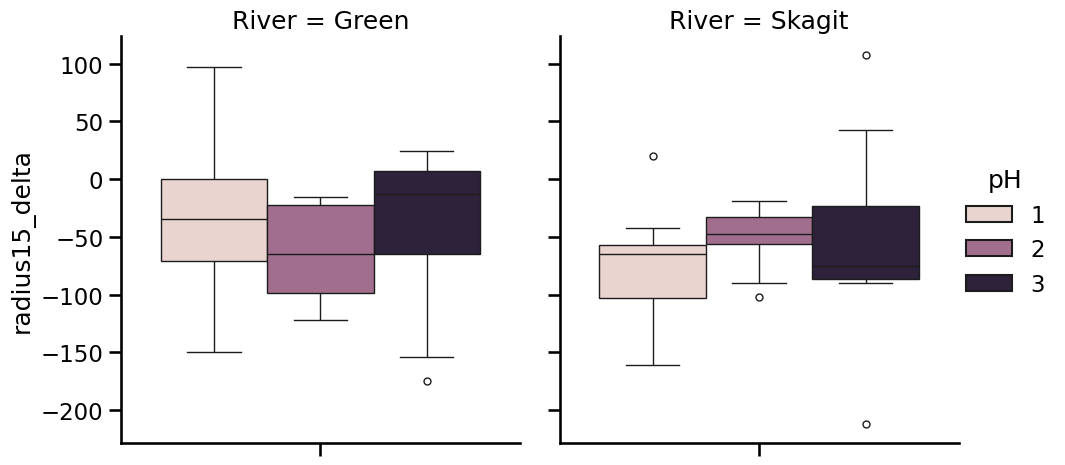

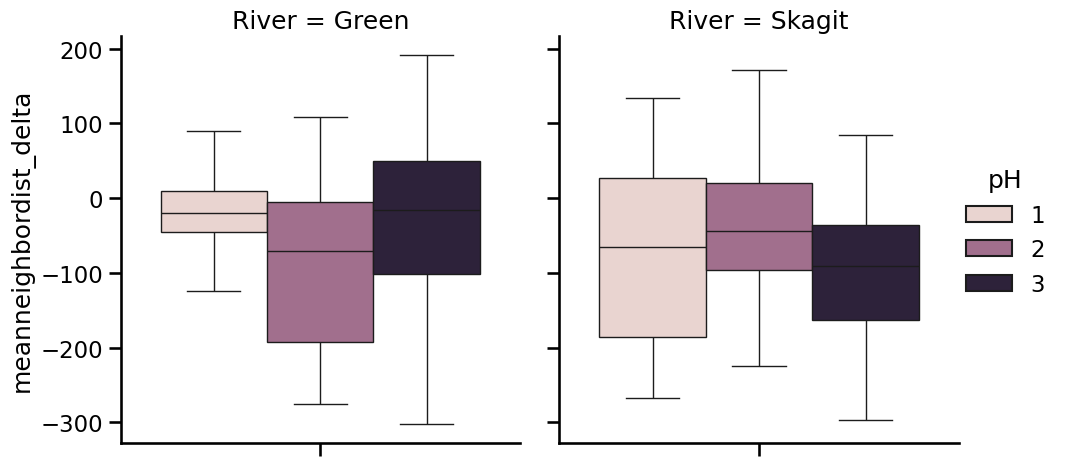

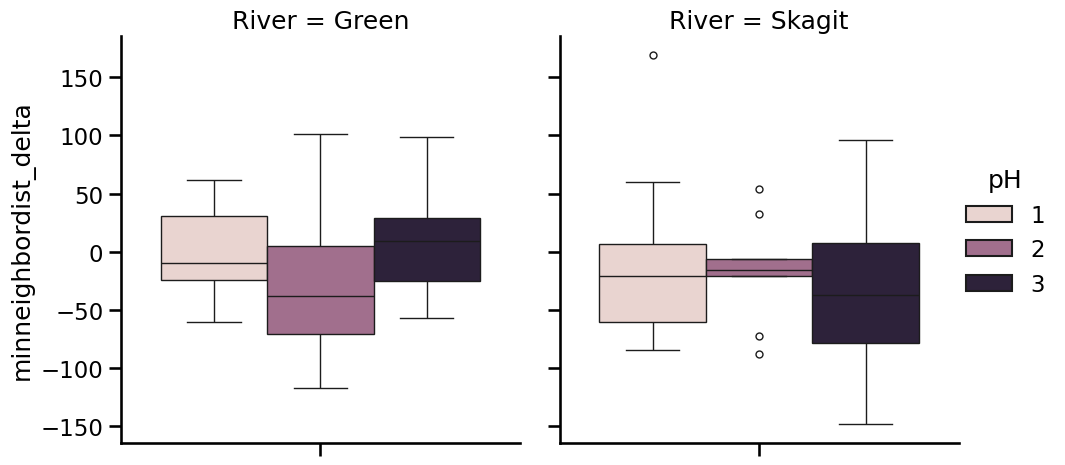

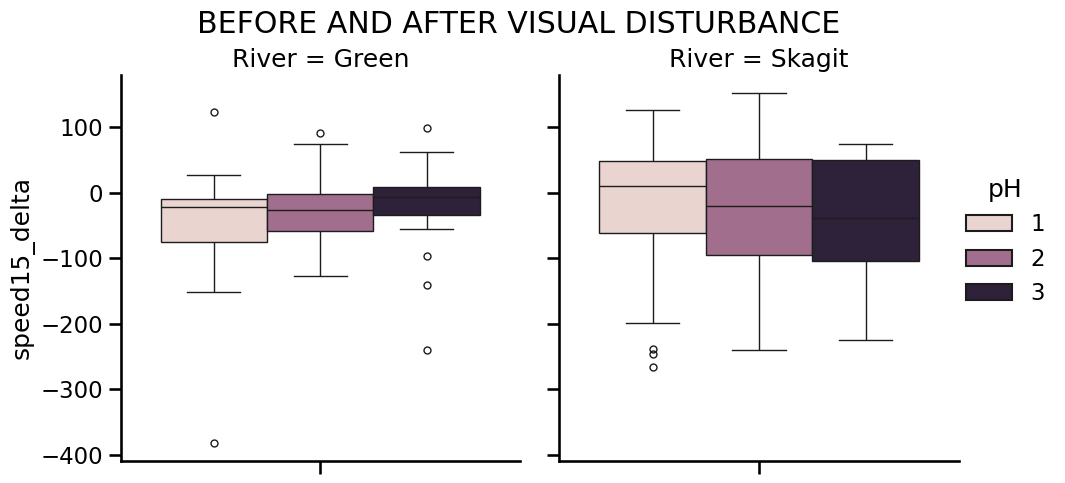

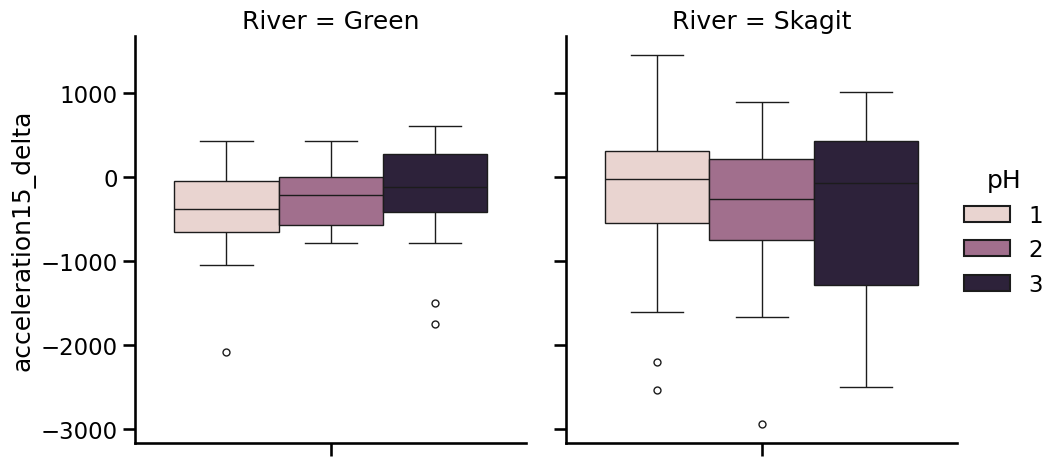

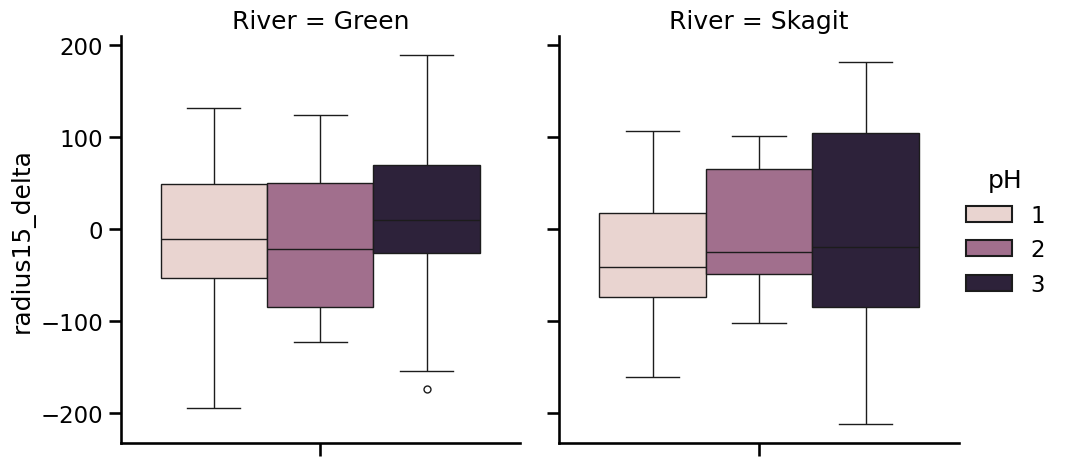

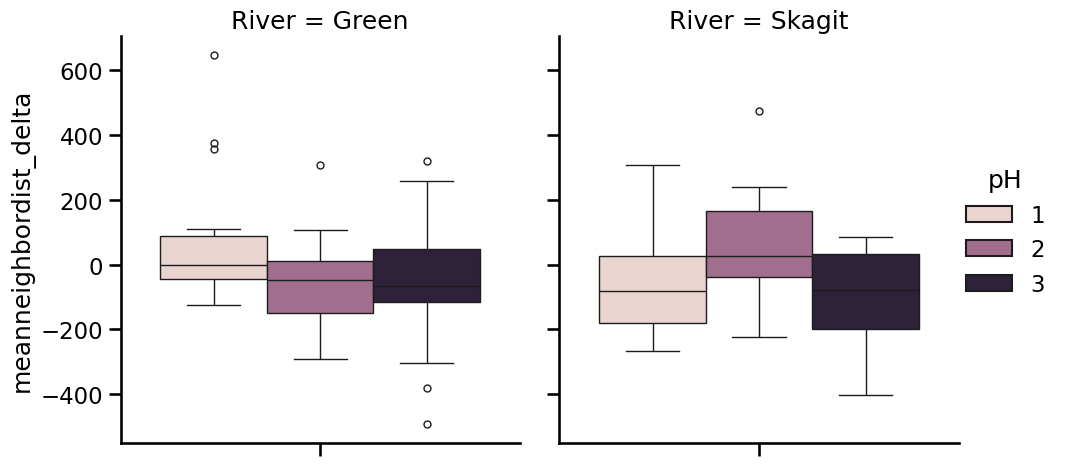

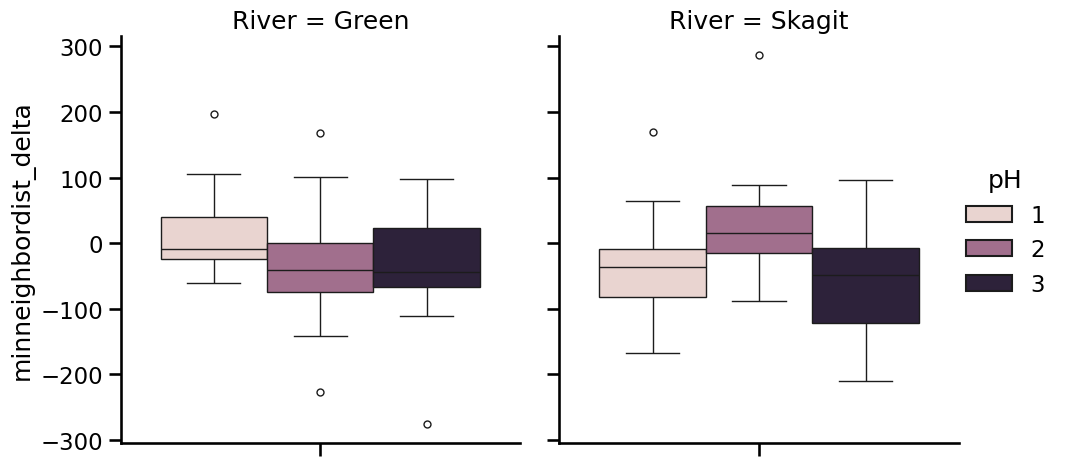

In [12]:
VARIABLES = [var + "_delta" for var in DELTA_VARS]

for deltas_df, title in [
    (skin_extract_deltas, "BEFORE AND AFTER SKIN EXTRACT"),
    (visual_disturbance_deltas, "BEFORE AND AFTER VISUAL DISTURBANCE"),
]:

    for i, var in enumerate(VARIABLES):
        p = sns.catplot(
            data=deltas_df, y=var, col="River", hue="pH",
            # kind="violin",
            kind="box"
            # stat="probability",
            # bins=10,
        )

        # p.set_yscale('log')
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)

